# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

La notebook corre en local, con el mismo entorno que `1-pre-processing.ipynb` y GPU.

Requisitos previos (en tu fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:
- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.
- Entregar esta notebook ejecutada, con sus salidas.

## Equipo
- Alumno 1 : Máximo Alva
- Alumno 2 : Zahir Jacob

## 1. Configuración del entorno

La configuración se define por variables de entorno **antes** de importar `lib`. No usamos PostgreSQL, para evaluar alcanza con los embeddings en memoria. Si hay GPU los modelos corren ahí, porque es mucho más rápido que en CPU.

In [1]:
# Librerías
import json
import logging
import os
import shutil
import sys
import time
import warnings
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from dotenv import load_dotenv
from sklearn.manifold import TSNE

# Aviso de tqdm por no tener ipywidgets, no lo usamos
warnings.filterwarnings("ignore", message="IProgress not found")

# Configuración del proyecto (antes de importar lib)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

os.environ["DATA_PATH"] = str(ROOT / "data")
os.environ["DATASET_PATH"] = str(ROOT / "data" / "dataset")
os.environ["OUTPUT_PATH"] = str(ROOT / "output")
os.environ["MODEL_PATH"] = str(ROOT / "models")
os.environ["TORCH_HOME"] = str(ROOT / "models" / "torch")
os.environ["USE_PGVECTOR"] = "false"
os.environ["YOLO_MODEL"] = "models/yolo11n.pt"
load_dotenv(ROOT / ".env.local.example")

from lib.bootstrap import build_classifier, build_detection, build_similarity, build_store
from lib.config import settings
from lib.evaluation.metrics import ndcg_at_k
from lib.models.cnn_custom import CNNCustom
from lib.preprocessing import bgr_to_rgb, load_bgr
from lib.schemas import Neighbor
from lib.training import TRAIN_CONFIGS, TrainConfig, confusion, load_splits, per_class_metrics, predict

# Logs con el mensaje solo, sin nivel ni módulo
logging.basicConfig(format="%(message)s", level=logging.INFO, force=True)

DATASET = Path(settings.dataset_path)
PROCESSED = ROOT / "data" / "processed"
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
SEED = 42

print("dataset_path:", Path(settings.dataset_path).relative_to(ROOT))
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data\dataset
GPU disponible: True


Quedó disponible la GPU, así que los embeddings se calculan ahí.

## 2. Dataset y splits

Usamos los splits de `1-pre-processing.ipynb` (`data/processed/splits.csv`), que ya tienen aplicado el filtrado. El conjunto independiente no está en el repositorio. Se descarga del link de la sección 6 de esa notebook y se descomprime en `data/dataset/independent/`.

Del conjunto independiente separamos las fotos de un solo perro, que tienen una raza correcta, de las escenas y las fotos sin perros, que no la tienen.

In [2]:
# Splits de la Parte 1
splits = pd.read_csv(PROCESSED / "splits.csv")

# Conjunto independiente, una carpeta por raza más las carpetas especiales
SPECIAL_FOLDERS = ("_Escenas", "_Sin perros")
independent = pd.DataFrame(
    [(p.relative_to(DATASET).as_posix(), p.parent.name)
     for p in sorted((DATASET / "independent").rglob("*")) if p.suffix.lower() in IMAGE_SUFFIXES],
    columns=["path", "breed"],
)
ind_dogs = independent[~independent["breed"].isin(SPECIAL_FOLDERS)].reset_index(drop=True)
ind_special = independent[independent["breed"].isin(SPECIAL_FOLDERS)].reset_index(drop=True)

print(splits["split"].value_counts().to_string())
print(f"independent    {len(independent)} ({len(ind_dogs)} de un perro, {len(ind_special)} escenas o sin perros)")

split
train    7539
test      700
valid     686
independent    136 (124 de un perro, 12 escenas o sin perros)


Quedan 7539 imágenes en train, 686 en valid y 700 en test. Del conjunto independiente, 124 fotos son de un solo perro y 12 son escenas o fotos sin perros.

## 3. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

La galería son las imágenes de `train` y las consultas son `test` y el conjunto independiente, que nunca se indexan. `valid` se usa solo para elegir `TOP_K` y el umbral.

No usamos la base de datos. Guardamos los embeddings de la galería en una matriz de numpy y buscamos con un producto matricial, que para miles de consultas es mucho más rápido.

### 3.1. Embeddings

Calculamos el embedding de cada imagen con `extract_embedding`, la misma función que usa la app, así medimos exactamente lo que hace la búsqueda. Como tarda unos minutos, los guardamos en `data/processed/embeddings_baseline.npz` y solo se recalculan si cambia la lista de imágenes.

In [3]:
# Servicio de la Etapa 1, el mismo que usa la app
similarity = build_similarity(settings, build_store(settings))

subsets = {
    "train": splits[splits["split"] == "train"].reset_index(drop=True),
    "valid": splits[splits["split"] == "valid"].reset_index(drop=True),
    "test": splits[splits["split"] == "test"].reset_index(drop=True),
    "independent": ind_dogs,
    "special": ind_special,
}

# Embeddings guardados de una corrida anterior, con el tiempo que tardaron
CACHE = PROCESSED / "embeddings_baseline.npz"
cache = dict(np.load(CACHE, allow_pickle=True)) if CACHE.exists() else {}

emb, seconds = {}, {}
for name, df in subsets.items():
    paths = df["path"].to_numpy()
    if f"{name}_seconds" in cache and np.array_equal(cache[f"{name}_paths"], paths):
        emb[name], seconds[name] = cache[name], float(cache[f"{name}_seconds"])
        continue
    start = time.perf_counter()
    emb[name] = np.array([similarity.extract_embedding(load_bgr(DATASET / p)) for p in paths], dtype=np.float32)
    seconds[name] = time.perf_counter() - start

np.savez(CACHE, **emb, **{f"{n}_paths": df["path"].to_numpy() for n, df in subsets.items()},
         **{f"{n}_seconds": s for n, s in seconds.items()})
for name, e in emb.items():
    print(f"{name:12s} {e.shape}  norma media {np.linalg.norm(e, axis=1).mean():.3f}  "
          f"{1000 * seconds[name] / len(e):.1f} ms por imagen, {seconds[name]:.0f} s en total")

Using JSON file vector store


train        (7539, 512)  norma media 1.000  4.9 ms por imagen, 37 s en total
valid        (686, 512)  norma media 1.000  4.6 ms por imagen, 3 s en total
test         (700, 512)  norma media 1.000  7.1 ms por imagen, 5 s en total
independent  (124, 512)  norma media 1.000  34.1 ms por imagen, 4 s en total
special      (12, 512)  norma media 1.000  21.4 ms por imagen, 0 s en total


Cada imagen quedó como un vector de 512 números con norma 1. Con la GPU tarda unos 5 ms por imagen del dataset, así que la galería de train se calcula en menos de un minuto. Las fotos del conjunto independiente tardan más, unos 34 ms, porque son mucho más grandes y hay que achicarlas.

### 3.2. Búsqueda y métricas

Con norma 1 la similitud coseno es directamente el producto escalar, así que buscar todas las consultas contra toda la galería es una sola multiplicación de matrices.

- `similarities` devuelve el score de cada consulta contra cada imagen de la galería, con la misma fórmula que `SimilarityService.similarity`.
- `evaluate` toma los 10 vecinos de cada consulta y calcula NDCG@10 y precision@10. Un vecino es relevante si es de la misma raza. Para el NDCG ideal usamos `n_relevant`, la cantidad de imágenes de esa raza en la galería. La raza predicha sale de `predict_breed_from_neighbors`, el mismo voto que usa la app.

In [4]:
# Galería
gallery = subsets["train"]
G = emb["train"]
gallery_breeds = gallery["breed"].to_numpy()
gallery_paths = gallery["path"].to_numpy()
n_por_raza = gallery["breed"].value_counts()


def similarities(Q: np.ndarray, metric: str = "cosine", gallery_emb: np.ndarray | None = None) -> np.ndarray:
    """Matriz (consultas, galeria) con el mismo score que SimilarityService.similarity. Por defecto usa la galeria del baseline."""
    cos = Q @ (G if gallery_emb is None else gallery_emb).T
    if metric == "cosine":
        return cos
    # Con norma 1, la distancia euclidea sale del coseno.
    return 1 / (1 + np.sqrt(np.maximum(2 - 2 * cos, 0)))


def evaluate(queries: pd.DataFrame, Q: np.ndarray, metric: str = "cosine", top_k: int = 10, threshold: float = 0.0,
             gallery_emb: np.ndarray | None = None) -> pd.DataFrame:
    """NDCG@10, precision@10 y raza predicha de cada consulta, con el voto de predict_breed_from_neighbors."""
    S = similarities(Q, metric, gallery_emb)
    order = np.argsort(-S, axis=1)[:, :max(top_k, 10)]
    similarity.similarity_threshold = threshold
    rows = []
    for i, breed in enumerate(queries["breed"]):
        idx = order[i]
        rel = (gallery_breeds[idx[:10]] == breed).astype(float)
        neighbors = [Neighbor(path=gallery_paths[j], breed=gallery_breeds[j], score=float(S[i, j])) for j in idx[:top_k]]
        pred, score = similarity.predict_breed_from_neighbors(neighbors)
        rows.append({
            "path": queries["path"].iat[i], "breed": breed, "pred": pred, "score": score,
            "top1": float(S[i, idx[0]]),
            "ndcg@10": ndcg_at_k(rel, k=10, n_relevant=int(n_por_raza.get(breed, 0))),
            "precision@10": rel.mean(),
        })
    res = pd.DataFrame(rows)
    res["correct"] = res["pred"] == res["breed"]
    return res


def summary(res: pd.DataFrame) -> dict:
    """Promedios de una evaluacion."""
    return {
        "NDCG@10": res["ndcg@10"].mean(),
        "precision@10": res["precision@10"].mean(),
        "accuracy": res["correct"].mean(),
        "unknown": (res["pred"] == "unknown").mean(),
    }

Así todas las evaluaciones de esta sección usan el mismo score y el mismo voto que la app.

### 3.3. Métricas en `test` y en el conjunto independiente

Primero medimos sin umbral, o sea que la app siempre responde la raza que gana el voto. El efecto del umbral lo vemos en la sección 3.6.

In [5]:
# Métricas medias, sin umbral
results = {name: evaluate(subsets[name], emb[name], "cosine", top_k=settings.top_k) for name in ("test", "independent")}

table = pd.DataFrame({name: summary(res) for name, res in results.items()}).T.drop(columns="unknown")
table.insert(0, "consultas", [len(res) for res in results.values()])
print(table.round(3).to_string())

             consultas  NDCG@10  precision@10  accuracy
test               700    0.873         0.860     0.934
independent        124    0.572         0.568     0.621


En `test` el NDCG@10 medio es **0,873** y la raza predicha es correcta en el **93,4 %** de las consultas. En el conjunto independiente baja a **0,572** y **62,1 %**.

#### Distribución del NDCG@10

Además del promedio miramos cómo se reparte el NDCG@10 entre las consultas.

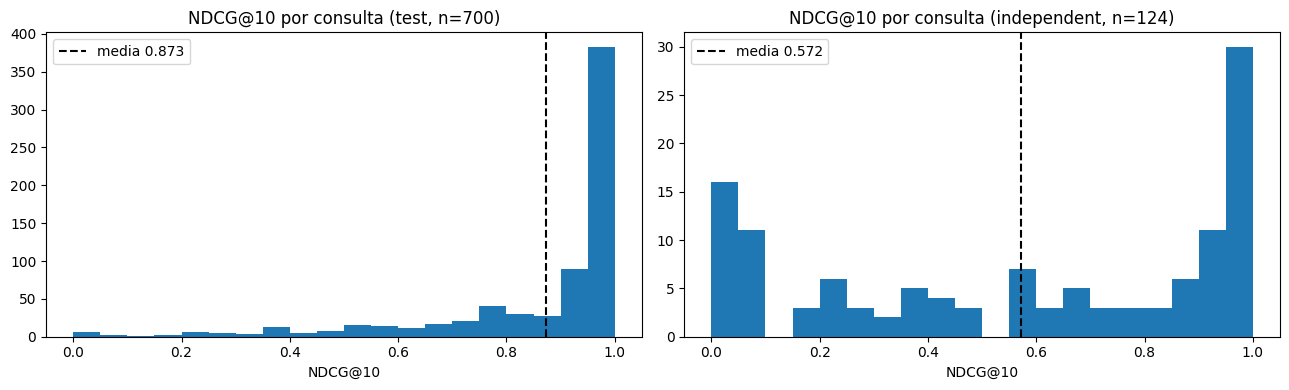

In [6]:
# Histograma del NDCG@10 de cada consulta
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, res) in zip(axes, results.items()):
    ax.hist(res["ndcg@10"], bins=20, range=(0, 1))
    ax.axvline(res["ndcg@10"].mean(), color="k", ls="--", label=f"media {res['ndcg@10'].mean():.3f}")
    ax.set_title(f"NDCG@10 por consulta ({name}, n={len(res)})")
    ax.set_xlabel("NDCG@10")
    ax.legend()
plt.tight_layout()
plt.show()

En `test` casi todas las consultas quedan cerca de 1, con una cola chica de consultas malas. En el conjunto independiente la distribución se parte en dos. Una parte de las fotos funciona igual de bien que en `test` y otra, cerca de 25 consultas, no recupera casi ningún vecino de su raza.

#### NDCG@10 por raza en `test`

Agrupamos por raza para ver cuáles funcionan peor.

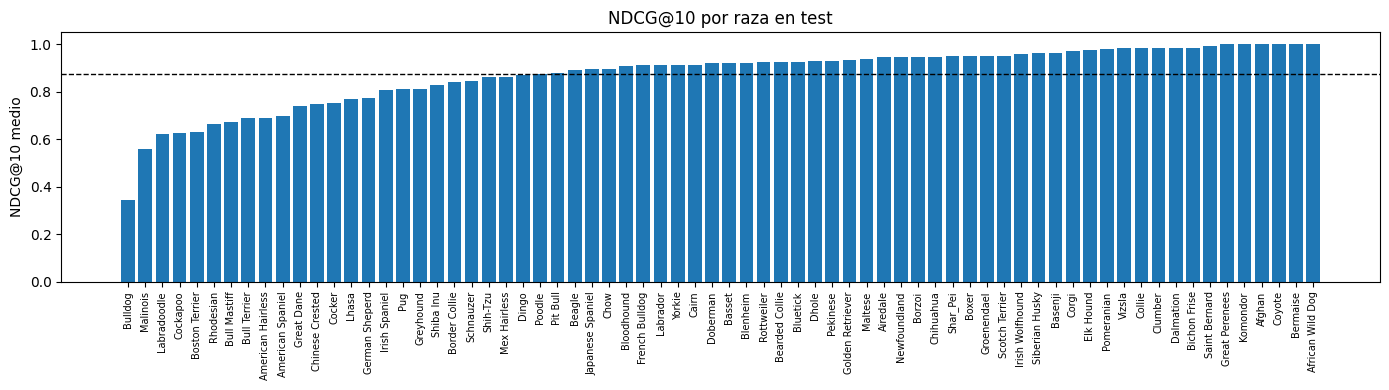

Razas con peor NDCG@10 en test:
                   ndcg@10  precision@10  correct
breed                                            
Bulldog              0.342          0.32      0.3
Malinois             0.559          0.50      0.8
Labradoodle          0.621          0.60      0.7
Cockapoo             0.628          0.59      0.8
Boston Terrier       0.629          0.62      0.8
Rhodesian            0.664          0.63      0.7
Bull Mastiff         0.673          0.68      0.7
Bull Terrier         0.687          0.64      0.7
American Hairless    0.691          0.65      0.7
American Spaniel     0.696          0.69      0.8


In [7]:
# NDCG@10 medio de cada raza
by_breed = results["test"].groupby("breed")[["ndcg@10", "precision@10", "correct"]].mean().sort_values("ndcg@10")

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(by_breed.index, by_breed["ndcg@10"])
ax.axhline(by_breed["ndcg@10"].mean(), color="k", ls="--", lw=1)
ax.set_ylabel("NDCG@10 medio")
ax.set_title("NDCG@10 por raza en test")
ax.tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout()
plt.show()

print("Razas con peor NDCG@10 en test:")
print(by_breed.head(10).round(3).to_string())

Las razas que peor andan son las que tienen otra muy parecida en el dataset, como Bulldog, Malinois, Labradoodle y Cockapoo, Boston Terrier o los perros sin pelo. Son los mismos grupos de razas parecidas de la sección 4.5 de `1-pre-processing.ipynb`. Bulldog es el caso más claro, con NDCG@10 de 0,342.

#### Conjunto independiente por raza

Hacemos lo mismo con el conjunto independiente y lo comparamos con el NDCG@10 de esa raza en `test`.

In [8]:
# Accuracy y NDCG@10 por raza en el conjunto independiente
ind_by_breed = results["independent"].groupby("breed").agg(
    fotos=("correct", "size"), accuracy=("correct", "mean"), ndcg=("ndcg@10", "mean")
).sort_values("ndcg")
ind_by_breed["ndcg en test"] = by_breed["ndcg@10"].reindex(ind_by_breed.index)
print(ind_by_breed.round(3).to_string())

                  fotos  accuracy   ndcg  ndcg en test
breed                                                 
Poodle                5     0.000  0.032         0.873
Greyhound            13     0.231  0.185         0.813
French Bulldog        5     0.400  0.229         0.910
Schnauzer             5     0.400  0.313         0.846
Maltese               6     0.500  0.349         0.939
Japanese Spaniel      5     0.400  0.387         0.894
Shih-Tzu              5     0.400  0.423         0.860
Pit Bull              5     0.400  0.446         0.879
German Sheperd        7     0.429  0.528         0.774
Labrador              6     0.833  0.557         0.910
Rottweiler            5     0.600  0.700         0.924
Border Collie        14     0.786  0.710         0.840
Beagle                5     0.800  0.746         0.892
Boxer                 8     0.875  0.764         0.950
Golden Retriever      5     0.800  0.802         0.935
Chihuahua             5     0.800  0.812         0.947
Bearded Co

Casi todas las razas bajan respecto de `test`, y algunas mucho, como Poodle (de 0,873 a 0,032), Greyhound y French Bulldog. Es un **cambio de dominio**. Las imágenes del dataset son recortes cerrados donde el perro ocupa casi todo el cuadro (sección 4.7 de `1-pre-processing.ipynb`), y las fotos reales tienen fondo, el perro más chico y otras poses. El embedding de ImageNet describe la imagen completa, así que el fondo también pesa en la búsqueda. Con 5 a 14 fotos por raza estos valores son orientativos.

### 3.4. Cosine vs. l2

Con embeddings de norma 1, la distancia euclídea sale del coseno (‖a − b‖² = 2 − 2·cos(a, b)), así que las dos métricas tendrían que ordenar los vecinos igual. Lo comprobamos.

In [9]:
# Métricas con cada métrica de similitud
comp = {}
for metric in ("cosine", "l2"):
    for name in ("test", "independent"):
        comp[(metric, name)] = summary(evaluate(subsets[name], emb[name], metric, top_k=settings.top_k))
print(pd.DataFrame(comp).T.drop(columns="unknown").round(3).to_string())

# Top-10 de cada consulta con las dos métricas
for n in ("test", "independent"):
    top_cos = np.argsort(-similarities(emb[n], "cosine"), axis=1)[:, :10]
    top_l2 = np.argsort(-similarities(emb[n], "l2"), axis=1)[:, :10]
    same_set = sum(set(a) == set(b) for a, b in zip(top_cos, top_l2))
    same_order = sum(np.array_equal(a, b) for a, b in zip(top_cos, top_l2))
    print(f"{n:12s} mismos 10 vecinos en {same_set} de {len(top_cos)} consultas, mismo orden en {same_order}")

                    NDCG@10  precision@10  accuracy
cosine test           0.873         0.860     0.934
       independent    0.572         0.568     0.621
l2     test           0.873         0.860     0.934
       independent    0.572         0.568     0.621


test         mismos 10 vecinos en 700 de 700 consultas, mismo orden en 699
independent  mismos 10 vecinos en 124 de 124 consultas, mismo orden en 124


**Las dos métricas dan exactamente los mismos resultados.** Los 10 vecinos son los mismos en todas las consultas. En una sola consulta de `test` cambia el orden de dos vecinos, porque tienen el mismo score y el empate se resuelve distinto, no porque las métricas ordenen distinto. Lo único que cambia es la escala del score, por eso el umbral no es el mismo número en las dos (sección 3.6). Dejamos `cosine`, que además es la que pgvector resuelve directamente en la base.

### 3.5. Efecto de `TOP_K`

`TOP_K` es la cantidad de vecinos que votan la raza. Lo elegimos con `valid` y miramos también cómo cambia en `test` y en el conjunto independiente.

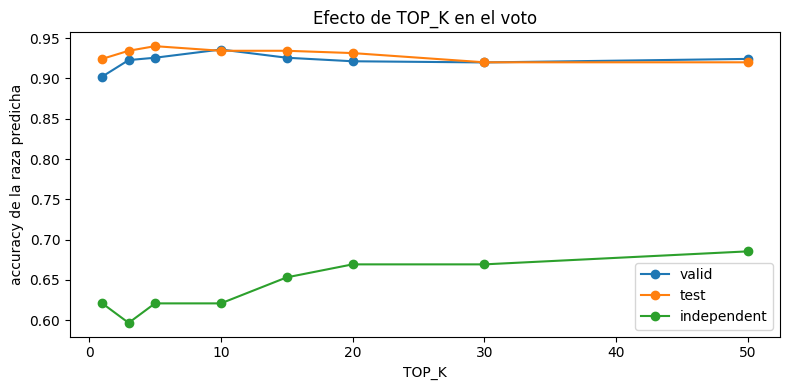

TOP_K           1      3      5      10     15     20     30     50
valid        0.902  0.923  0.926  0.936  0.926  0.921  0.920  0.924
test         0.924  0.934  0.940  0.934  0.934  0.931  0.920  0.920
independent  0.621  0.597  0.621  0.621  0.653  0.669  0.669  0.685


In [10]:
# Accuracy de la raza predicha para distintos TOP_K
TOP_KS = [1, 3, 5, 10, 15, 20, 30, 50]
topk = pd.DataFrame({
    "valid": [evaluate(subsets["valid"], emb["valid"], "cosine", top_k=k)["correct"].mean() for k in TOP_KS],
    "test": [evaluate(subsets["test"], emb["test"], "cosine", top_k=k)["correct"].mean() for k in TOP_KS],
    "independent": [evaluate(subsets["independent"], emb["independent"], "cosine", top_k=k)["correct"].mean() for k in TOP_KS],
}, index=pd.Index(TOP_KS, name="TOP_K"))

ax = topk.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("accuracy de la raza predicha")
ax.set_title("Efecto de TOP_K en el voto")
plt.tight_layout()
plt.show()
print(topk.round(3).T.to_string())

En `valid` el mejor valor es **10** (93,6 %). Con 1 vecino la predicción depende de una sola imagen y empeora, y con más de 10 entran vecinos de otras razas que meten ruido en el voto. Dejamos `TOP_K=10`, que además es la cantidad de vecinos que muestra la app. En el conjunto independiente la accuracy sube con más vecinos (de 62 % a 69 % con 50), pero son 124 imágenes y no se usan para elegir.

### 3.6. Umbral de `unknown`

Si el mejor vecino queda por debajo de `SIMILARITY_THRESHOLD`, la app responde `unknown`. Para calibrarlo hacen falta consultas que la app **no** debería reconocer, y en `valid` no hay, porque todas sus razas están en la galería.

Las simulamos. Cada consulta de `valid` se busca dos veces.
- Raza conocida, contra toda la galería. Si el mejor score queda por debajo del umbral, es un perro conocido rechazado (FRR).
- Raza desconocida, contra la galería sin las imágenes de su raza. Si el mejor score supera el umbral, la app le asigna una raza que no es la suya (FAR).

Subir el umbral baja el FAR y sube el FRR. Comparamos dos criterios.
- EER, el punto donde FAR y FRR son iguales.
- FRR del 5 %, que prioriza no rechazar perros de razas conocidas.

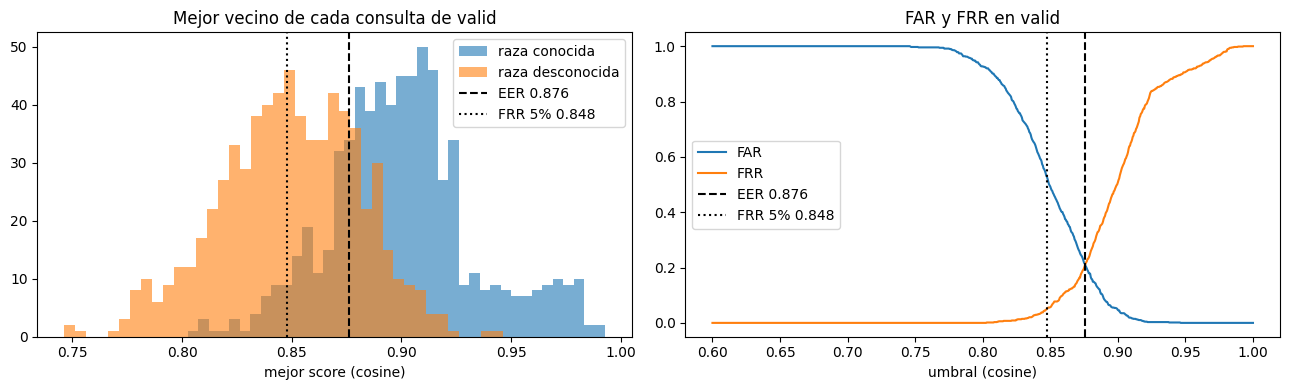

EER     umbral 0.876  FAR 20.7%  FRR 21.3%  (en l2 equivale a 0.668)
FRR 5%  umbral 0.848  FAR 52.5%  FRR 5.1%  (en l2 equivale a 0.644)


In [11]:
def calibration_scores(Q: np.ndarray, breeds: np.ndarray, metric: str = "cosine") -> tuple[np.ndarray, np.ndarray]:
    """Mejor score de cada consulta con su raza en la galeria (conocida) y sin ella (desconocida)."""
    S = similarities(Q, metric)
    known = S.max(axis=1)
    same_breed = gallery_breeds[None, :] == breeds[:, None]
    unknown = np.where(same_breed, -np.inf, S).max(axis=1)
    return known, unknown


def far_frr(known: np.ndarray, unknown: np.ndarray, grid: np.ndarray) -> pd.DataFrame:
    """FAR y FRR para cada umbral de la grilla."""
    return pd.DataFrame({
        "threshold": grid,
        "FRR": [(known < t).mean() for t in grid],
        "FAR": [(unknown >= t).mean() for t in grid],
    })


# Scores de valid y umbral de cada criterio
valid_breeds = subsets["valid"]["breed"].to_numpy()
known, unknown = calibration_scores(emb["valid"], valid_breeds)
curve = far_frr(known, unknown, np.linspace(0.6, 1.0, 801))

candidates = {
    "EER": float(curve.loc[(curve["FAR"] - curve["FRR"]).abs().idxmin(), "threshold"]),
    "FRR 5%": float(np.quantile(known, 0.05)),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(known, bins=40, alpha=0.6, label="raza conocida")
axes[0].hist(unknown, bins=40, alpha=0.6, label="raza desconocida")
axes[0].set_xlabel("mejor score (cosine)")
axes[0].set_title("Mejor vecino de cada consulta de valid")
axes[1].plot(curve["threshold"], curve["FAR"], label="FAR")
axes[1].plot(curve["threshold"], curve["FRR"], label="FRR")
axes[1].set_xlabel("umbral (cosine)")
axes[1].set_title("FAR y FRR en valid")
for ax in axes:
    for (name, t), ls in zip(candidates.items(), ("--", ":")):
        ax.axvline(t, color="k", ls=ls, label=f"{name} {t:.3f}")
    ax.legend()
plt.tight_layout()
plt.show()

for name, t in candidates.items():
    print(f"{name:7s} umbral {t:.3f}  FAR {(unknown >= t).mean():.1%}  FRR {(known < t).mean():.1%}  (en l2 equivale a {1 / (1 + np.sqrt(2 - 2 * t)):.3f})")

Las dos distribuciones se pisan mucho, porque un perro siempre se parece a otro perro. El mejor vecino de una raza conocida da en promedio 0,90 y el de una raza desconocida 0,85. El EER queda en **0,876** con un 21 % de error de cada lado. Con FRR 5 % el umbral baja a **0,848**, pero acepta más de la mitad de las razas desconocidas.

#### Efecto del umbral en `test` y en el conjunto independiente

Aplicamos los dos umbrales a las consultas y vemos cuánto cae la accuracy y cuántas consultas pasan a `unknown`.

In [12]:
# Accuracy y porcentaje de unknown con cada umbral
rows = {}
for name in ("test", "independent"):
    for crit, t in {"sin umbral": 0.0, **candidates}.items():
        res = evaluate(subsets[name], emb[name], "cosine", top_k=settings.top_k, threshold=t)
        rows[(name, crit)] = {"umbral": round(t, 3), "accuracy %": 100 * res["correct"].mean(), "unknown %": 100 * (res["pred"] == "unknown").mean()}
print(pd.DataFrame(rows).T.to_string(formatters={"umbral": "{:.3f}".format, "accuracy %": "{:.1f}".format, "unknown %": "{:.1f}".format}))

                       umbral accuracy % unknown %
test        sin umbral  0.000       93.4       0.0
            EER         0.876       72.3      23.0
            FRR 5%      0.848       89.1       4.9
independent sin umbral  0.000       62.1       0.0
            EER         0.876       12.1      87.1
            FRR 5%      0.848       33.9      61.3


En `test` el umbral de FRR 5 % casi no afecta (89,1 % de acierto y 4,9 % de `unknown`), mientras que el EER manda a `unknown` al 23 % de las consultas. En el conjunto independiente los dos rechazan a la mayoría de los perros, el 61,3 % con FRR 5 % y el 87,1 % con el EER.

#### Escenas y fotos sin perros

El conjunto independiente también tiene escenas y fotos sin perros, que no tienen una raza correcta. Comparamos el mejor score de cada tipo de imagen con los dos umbrales.

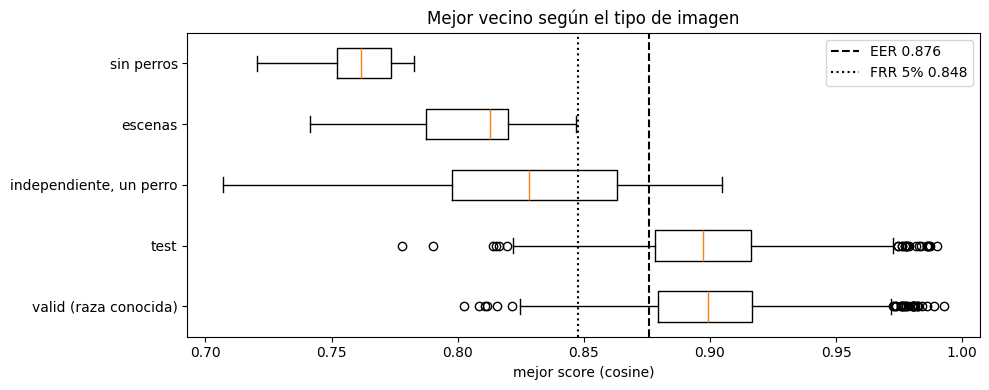

      breed                           path             pred     top1
   _Escenas    independent/_Escenas/05.jpg            Corgi 0.741464
   _Escenas    independent/_Escenas/01.jpg         Shih-Tzu 0.781181
   _Escenas    independent/_Escenas/04.jpg        Greyhound 0.806260
   _Escenas    independent/_Escenas/03.jpg   Great Perenees 0.819086
   _Escenas    independent/_Escenas/02.jpg Golden Retriever 0.820023
   _Escenas    independent/_Escenas/06.jpg           Beagle 0.847101
_Sin perros independent/_Sin perros/02.jpg        Schnauzer 0.720286
_Sin perros independent/_Sin perros/04.jpg         Malinois 0.750312
_Sin perros independent/_Sin perros/05.jpg          Bulldog 0.757410
_Sin perros independent/_Sin perros/06.jpg         Shar_Pei 0.766183
_Sin perros independent/_Sin perros/03.jpg         Malinois 0.775986
_Sin perros independent/_Sin perros/01.jpg    Border Collie 0.782577


In [13]:
# Mejor score según el tipo de imagen
special = evaluate(subsets["special"], emb["special"], "cosine", top_k=settings.top_k)
groups = {
    "valid (raza conocida)": known,
    "test": results["test"]["top1"],
    "independiente, un perro": results["independent"]["top1"],
    "escenas": special.loc[special["breed"] == "_Escenas", "top1"],
    "sin perros": special.loc[special["breed"] == "_Sin perros", "top1"],
}

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(list(groups.values()), vert=False)
ax.set_yticks(range(1, len(groups) + 1), list(groups))
for (name, t), ls in zip(candidates.items(), ("--", ":")):
    ax.axvline(t, color="k", ls=ls, label=f"{name} {t:.3f}")
ax.set_xlabel("mejor score (cosine)")
ax.set_title("Mejor vecino según el tipo de imagen")
ax.legend()
plt.tight_layout()
plt.show()

print(special[["breed", "path", "pred", "top1"]].sort_values(["breed", "top1"]).to_string(index=False))

Las fotos sin perros quedan entre 0,72 y 0,78, por debajo de los dos umbrales, y las escenas entre 0,74 y 0,85. El problema es que los perros reales del conjunto independiente caen en el mismo rango, por el cambio de dominio. Con estos embeddings no hay un umbral que rechace las fotos sin perros sin rechazar también a muchos perros reales.

**Decisión.** El umbral depende de los embeddings, y la app va a usar los del modelo que elijamos en la sección 10. Por eso el valor final de `SIMILARITY_THRESHOLD` se calibra ahí, con este mismo procedimiento sobre `valid` y los embeddings elegidos. En la Etapa 3, además, las imágenes sin perros las descarta YOLO antes de clasificar.

### 3.7. Análisis de errores

Contamos qué razas se confunden con cuáles en `test`.

In [14]:
# Pares (raza real, raza predicha) más frecuentes entre los errores
errors = results["test"][~results["test"]["correct"]]
pairs = errors.groupby(["breed", "pred"]).size().sort_values(ascending=False).rename("errores")
print(f"Errores en test: {len(errors)} de {len(results['test'])}")
print(pairs.head(15).to_string())

Errores en test: 46 de 700
breed              pred             
Bulldog            Boston Terrier       4
American Hairless  Mex Hairless         3
Bull Mastiff       Boxer                3
Labradoodle        Cockapoo             3
Bull Terrier       Basenji              2
American Spaniel   Irish Spaniel        2
Cockapoo           Labradoodle          2
Bulldog            French Bulldog       2
German Sheperd     Malinois             2
Boston Terrier     Bulldog              2
Rhodesian          Vizsla               2
Chinese Crested    American Hairless    1
Bull Terrier       Pit Bull             1
Bulldog            Boxer                1
Cocker             Saint Bernard        1


Hay 46 errores en 700 consultas y casi todos son entre razas muy parecidas, como Bulldog con Boston Terrier o French Bulldog, American Hairless con Mex Hairless, Labradoodle con Cockapoo o American con Irish Spaniel.

#### Ejemplos de `test`

Mostramos las 6 consultas de `test` con peor NDCG@10 junto a sus 10 vecinos. El nombre de cada vecino va en verde si es de la misma raza que la consulta y en rojo si no. Como son los peores casos, casi todos los vecinos son de otra raza y aparecen en rojo.

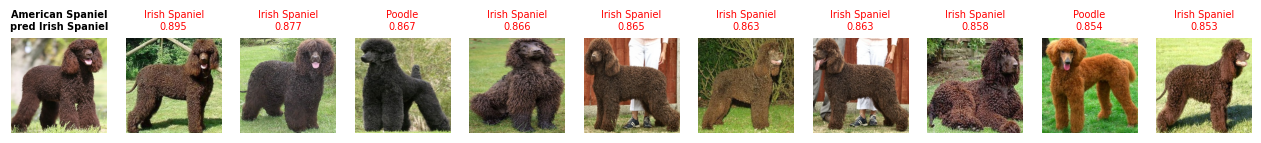

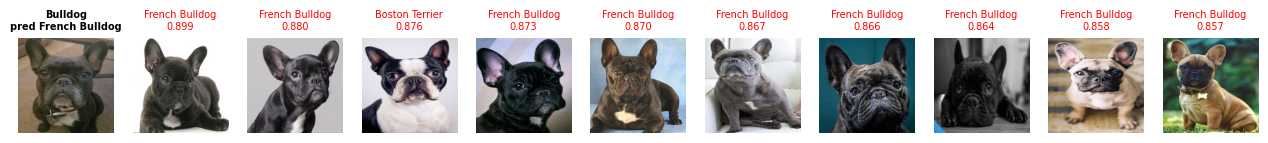

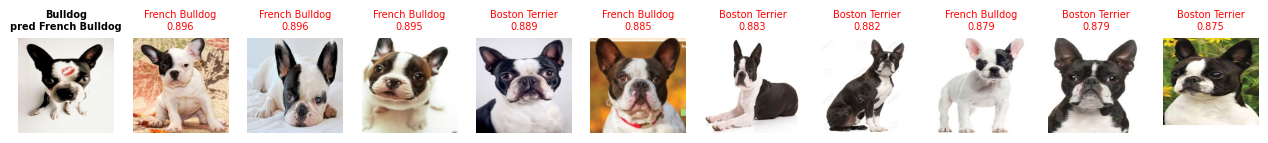

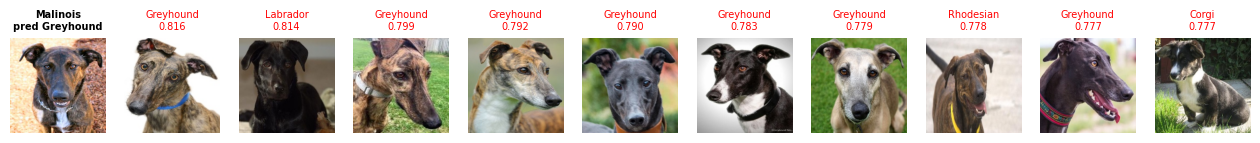

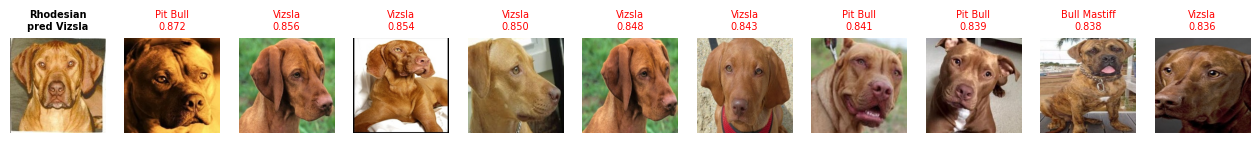

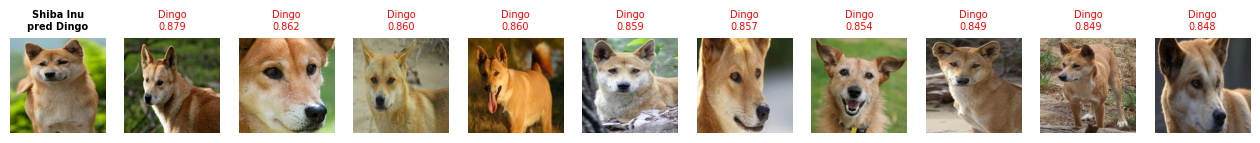

In [15]:
def show_query(res_row: pd.Series, Q: np.ndarray) -> None:
    """Consulta y sus Top-10, en verde los vecinos de la misma raza."""
    s = similarities(Q[[res_row.name]])[0]
    idx = np.argsort(-s)[:10]
    fig, axes = plt.subplots(1, 11, figsize=(16, 2.2))
    axes[0].imshow(bgr_to_rgb(load_bgr(DATASET / res_row["path"])))
    axes[0].set_title(f"{res_row['breed']}\npred {res_row['pred']}", fontsize=7, fontweight="bold")
    for ax, j in zip(axes[1:], idx):
        ax.imshow(bgr_to_rgb(load_bgr(DATASET / gallery_paths[j])))
        color = "green" if gallery_breeds[j] == res_row["breed"] else "red"
        ax.set_title(f"{gallery_breeds[j]}\n{s[j]:.3f}", fontsize=7, color=color)
    for ax in axes:
        ax.axis("off")
    plt.show()


# Las 6 consultas de test con peor NDCG@10
for _, row in errors.sort_values("ndcg@10").head(6).iterrows():
    show_query(row, emb["test"])

En algunos ejemplos la consulta se parece más a la raza predicha que a su etiqueta. El Bulldog del segundo ejemplo tiene las orejas y la cara de un French Bulldog, así que parte de estos errores pueden ser errores de etiqueta del dataset.

#### Ejemplos que funcionan en `test`

Para comparar, mostramos tres consultas de `test` de razas distintas con NDCG@10 igual a 1, o sea con los 10 vecinos de la misma raza.

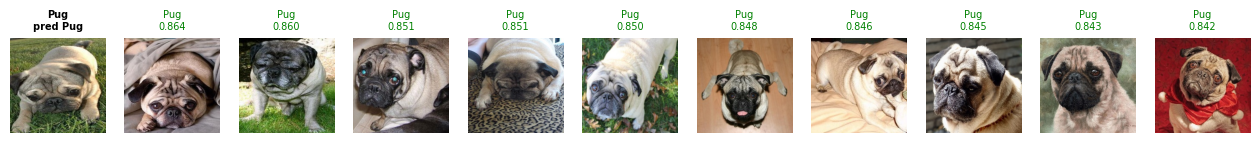

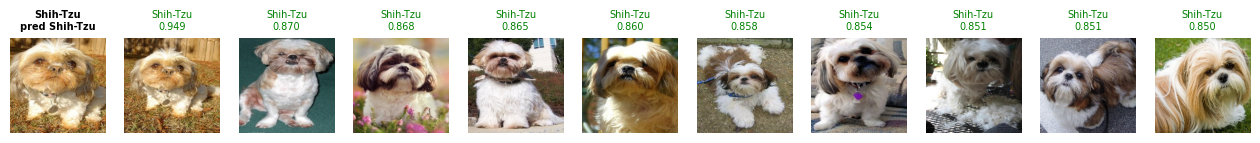

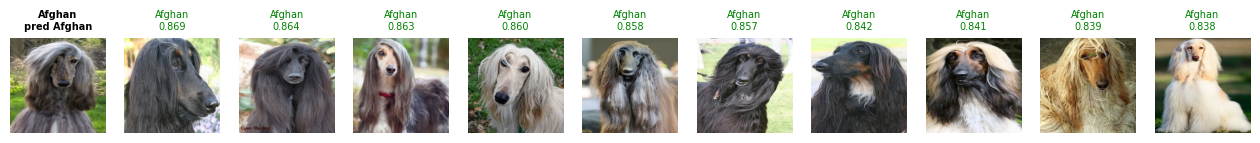

In [16]:
# Tres consultas de test con los 10 vecinos correctos, de razas distintas
good_test = results["test"][results["test"]["ndcg@10"] == 1].drop_duplicates("breed").sample(3, random_state=SEED)
for _, row in good_test.iterrows():
    show_query(row, emb["test"])

Cuando la raza tiene rasgos bien marcados, como la cara chata del Pug o el pelo largo del Shih-Tzu y del Afghan, los 10 vecinos son de la misma raza aunque cambien la pose, el color y el fondo. En el Shih-Tzu el primer vecino tiene un score de 0,949 y parece el mismo perro en una foto casi igual, que no llegó a detectarse como duplicado en la Parte 1.

#### Ejemplos del conjunto independiente

Hacemos lo mismo con las fotos reales.

Errores en el conjunto independiente: 47 de 124


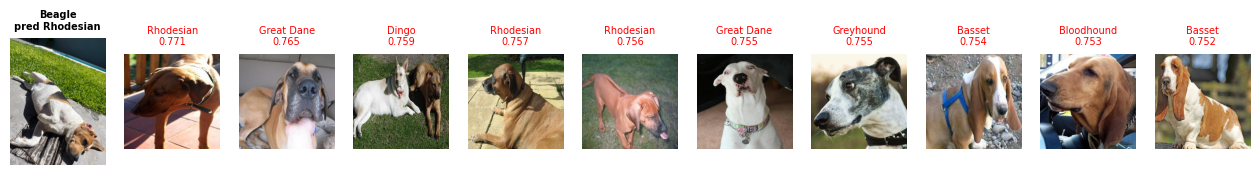

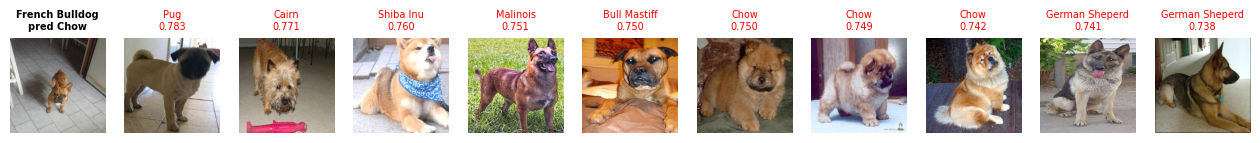

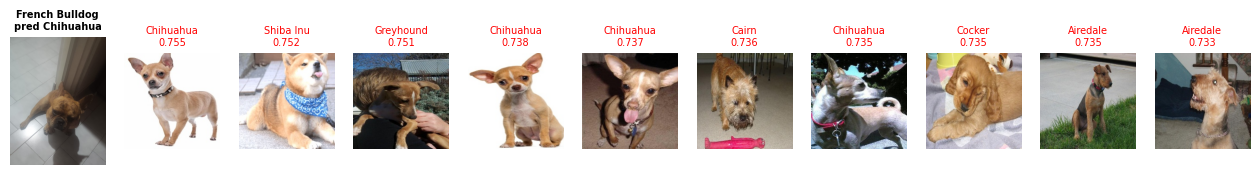

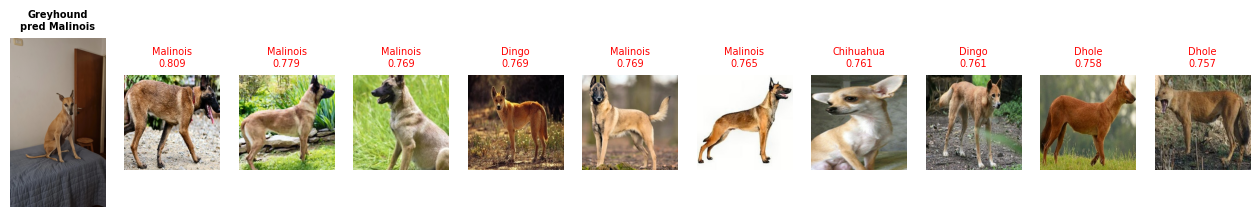

In [17]:
# Las 4 consultas del conjunto independiente con peor NDCG@10
ind_errors = results["independent"][~results["independent"]["correct"]]
print(f"Errores en el conjunto independiente: {len(ind_errors)} de {len(results['independent'])}")
for _, row in ind_errors.sort_values("ndcg@10").head(4).iterrows():
    show_query(row, emb["independent"])

Hay 47 errores en 124 fotos, y aparecen errores que en `test` casi no hay. Cuando el perro ocupa poco del cuadro, como el French Bulldog en el piso, los vecinos se eligen por el fondo y el color y salen razas sin relación. La pose también pesa, el Greyhound sentado de perfil recupera Malinois y dingos del mismo color.

#### Ejemplos que funcionan en el conjunto independiente

También hay fotos reales donde la búsqueda funciona bien. Mostramos las tres de mejor NDCG@10, de razas distintas.

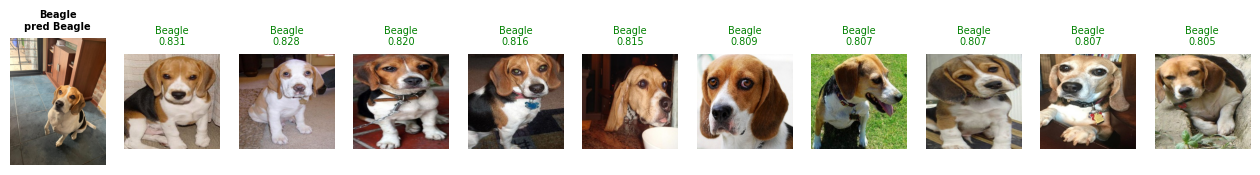

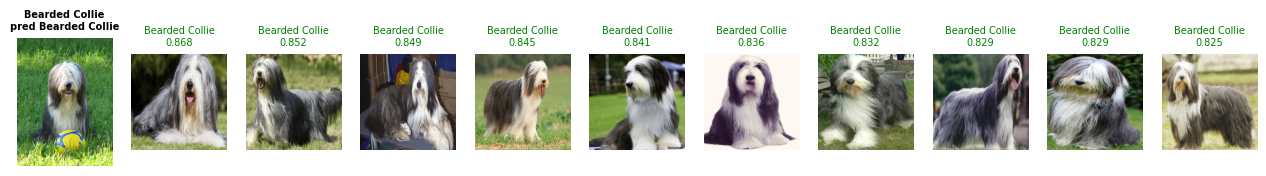

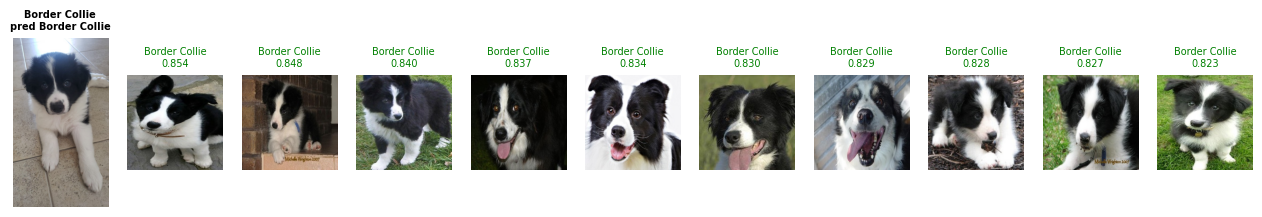

In [18]:
# Las tres fotos reales con mejor NDCG@10, de razas distintas
good_ind = results["independent"].sort_values("ndcg@10", ascending=False).drop_duplicates("breed").head(3)
for _, row in good_ind.iterrows():
    show_query(row, emb["independent"])

En las fotos reales que funcionan el pelaje es muy característico, como el tricolor del Beagle, el pelo largo gris y blanco del Bearded Collie o el blanco y negro del Border Collie. Los scores son más bajos que en `test` (entre 0,80 y 0,87), pero los 10 vecinos son de la raza correcta. El cambio de dominio no afecta a todas las fotos por igual. Las razas con un pelaje fácil de reconocer se siguen encontrando aunque haya fondo, y las que fallan son sobre todo las de perros chicos en el cuadro o en poses poco comunes.

## 4. Modelo A (obligatorio): fine-tuning de ResNet

`train_classifier` debe guardar el checkpoint en `models/resnet18_finetuned.pth`
(o el nombre configurado en `RESNET18_MODEL_NAME`). Documentar la estrategia de fine-tuning
y los hiperparámetros utilizados (learning rate, batch size, epochs, optimizador, scheduler,
regularización).

### 4.1. Estrategias de entrenamiento

Partimos de la ResNet18 preentrenada en ImageNet, la misma del baseline, y cambiamos la última capa por una lineal con una salida por raza. El embedding sigue siendo de 512, así la comparación con el baseline mide solo el efecto del entrenamiento.

Probamos dos estrategias. En feature extraction la red queda congelada, BatchNorm incluido, y solo se entrena la última capa. En fine-tuning completo se entrena toda la red con dos learning rates, 1e-3 para la última capa, que arranca de cero, y 1e-4 para el resto. Con el learning rate más chico las capas preentrenadas se ajustan a las razas sin perder lo que aprendieron en ImageNet.

El resto es igual para las dos. Usamos AdamW con weight decay de 1e-4 y label smoothing de 0,1, para que el modelo no se vuelva demasiado confiado con razas muy parecidas. Si la loss de valid no mejora en 2 épocas el learning rate se divide por 10, y si no mejora en 5 se corta el entrenamiento y queda el checkpoint de la mejor época. El batch es de 64, con hasta 30 épocas y el augmentation de la sección 8 de `1-pre-processing.ipynb`, solo en train.

In [19]:
# Servicio de la Etapa 2 y configuración de cada estrategia
classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")

configs = {
    "frozen": TrainConfig(strategy="frozen", checkpoint=Path(settings.model_path) / "resnet18_frozen.pth"),
    "finetune": TrainConfig(strategy="finetune"),
}
print(pd.DataFrame({name: asdict(c) for name, c in configs.items()}).drop("checkpoint").to_string())

                             frozen            finetune
strategy                     frozen            finetune
augment                        True                True
epochs                           30                  30
batch_size                       64                  64
lr_head                       0.001               0.001
lr_backbone                  0.0001              0.0001
weight_decay                 0.0001              0.0001
label_smoothing                 0.1                 0.1
lr_patience                       2                   2
early_stopping                    5                   5
num_workers                       4                   4
seed                             42                  42
channels         (32, 64, 128, 256)  (32, 64, 128, 256)
convs_per_block                   1                   1
embedding_dim                   512                 512
dropout                         0.3                 0.3


Las dos configuraciones solo cambian en la estrategia. El fine-tuning se guarda en `models/resnet18_finetuned.pth`, que es el checkpoint que usa la app, y feature extraction en `models/resnet18_frozen.pth`, solo para comparar.

### 4.2. Feature extraction

Entrenamos solo la última capa. El log muestra la loss y la accuracy de train y valid de cada época, y marca con "(mejor)" las épocas en que se guarda el checkpoint.

In [20]:
# Entrenamiento con la red congelada
TRAIN_CONFIGS["resnet18_finetuned"] = configs["frozen"]
classifier.train_classifier()

Entrenando resnet18_finetuned (frozen) en cuda, 35910 parametros entrenables


Epoca  1  train loss 2.439 acc 0.575  valid loss 1.300 acc 0.907  lr 1e-03  69 s  (mejor)


Epoca  2  train loss 1.495 acc 0.817  valid loss 1.187 acc 0.921  lr 1e-03  9 s  (mejor)


Epoca  3  train loss 1.387 acc 0.844  valid loss 1.160 acc 0.926  lr 1e-03  8 s  (mejor)


Epoca  4  train loss 1.332 acc 0.858  valid loss 1.154 acc 0.936  lr 1e-03  9 s  (mejor)


Epoca  5  train loss 1.310 acc 0.867  valid loss 1.149 acc 0.923  lr 1e-03  8 s  (mejor)


... (22 outputs left out)

Epoca 28  train loss 1.165 acc 0.913  valid loss 1.084 acc 0.943  lr 1e-04  8 s


Epoca 29  train loss 1.156 acc 0.919  valid loss 1.082 acc 0.943  lr 1e-04  8 s  (mejor)


Epoca 30  train loss 1.150 acc 0.921  valid loss 1.081 acc 0.942  lr 1e-04  9 s  (mejor)


Se guardaron resnet18_frozen.pth y history_resnet18_frozen.json


Con la red congelada solo se entrenan los 35.910 parámetros de la última capa. Ya en la primera época pasa el 90 % en valid, porque los embeddings de ImageNet separan bien las razas, igual que en la búsqueda de la sección 3. Después mejora poco y termina en la época 30 con 94,2 %.

### 4.3. Fine-tuning completo

Ahora entrenamos toda la red, con el learning rate más chico en las capas preentrenadas.

In [21]:
# Entrenamiento de toda la red
TRAIN_CONFIGS["resnet18_finetuned"] = configs["finetune"]
classifier.train_classifier()

Entrenando resnet18_finetuned (finetune) en cuda, 11212422 parametros entrenables


Epoca  1  train loss 2.111 acc 0.627  valid loss 1.173 acc 0.901  lr 1e-03  79 s  (mejor)


Epoca  2  train loss 1.317 acc 0.849  valid loss 1.098 acc 0.924  lr 1e-03  18 s  (mejor)


Epoca  3  train loss 1.189 acc 0.893  valid loss 1.053 acc 0.952  lr 1e-03  18 s  (mejor)


Epoca  4  train loss 1.109 acc 0.923  valid loss 1.046 acc 0.955  lr 1e-03  18 s  (mejor)


Epoca  5  train loss 1.070 acc 0.932  valid loss 1.028 acc 0.948  lr 1e-03  18 s  (mejor)


... (22 outputs left out)

Epoca 28  train loss 0.828 acc 0.996  valid loss 0.953 acc 0.962  lr 1e-05  18 s


Epoca 29  train loss 0.827 acc 0.996  valid loss 0.950 acc 0.965  lr 1e-05  18 s


Early stopping en la epoca 29


Se guardaron resnet18_finetuned.pth y history_resnet18_finetuned.json


Se entrenan los 11,2 millones de parámetros y cada época tarda el doble que con la red congelada. Valid pasa el 95 % en la época 3 y la mejor época es la 24, con 96,6 %. El early stopping corta en la 29.

### 4.4. Curvas de entrenamiento

Graficamos la loss y la accuracy de train y valid de las dos estrategias, con la época elegida marcada. La accuracy de train se mide con augmentation y la loss con label smoothing, por eso puede quedar por debajo de valid.

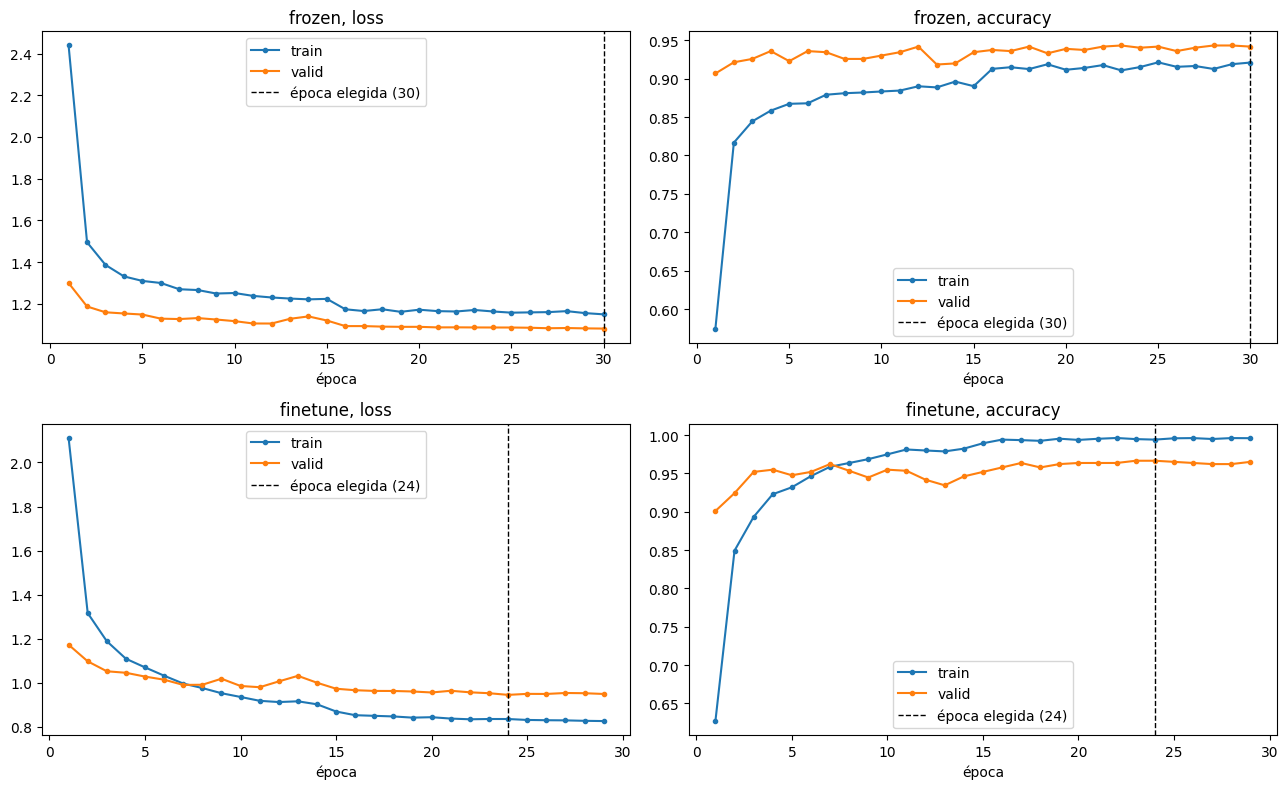

In [22]:
# Historial por época de cada entrenamiento
histories = {
    name: pd.DataFrame(json.loads((Path(settings.output_path) / f"history_{ckpt}.json").read_text(encoding="utf-8"))["history"])
    for name, ckpt in (("frozen", "resnet18_frozen"), ("finetune", "resnet18_finetuned"))
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (name, h) in enumerate(histories.items()):
    best = int(h.loc[h["valid_loss"].idxmin(), "epoch"])
    for col, metric in enumerate(("loss", "acc")):
        ax = axes[row, col]
        ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", ms=3, label="train")
        ax.plot(h["epoch"], h[f"valid_{metric}"], marker="o", ms=3, label="valid")
        ax.axvline(best, color="k", ls="--", lw=1, label=f"época elegida ({best})")
        ax.set_title(f"{name}, {'loss' if metric == 'loss' else 'accuracy'}")
        ax.set_xlabel("época")
        ax.legend()
plt.tight_layout()
plt.show()

Con la red congelada no hay overfitting. Train queda por debajo de valid todo el entrenamiento, porque se mide con augmentation, y las dos curvas se aplanan juntas. El techo lo pone la red congelada, que no puede adaptar sus filtros a las razas.

Con fine-tuning, train llega casi al 100 % y valid se queda cerca del 96 %, así que hay algo de overfitting. Igual la loss de valid baja hasta la época 24, y el checkpoint guardado es el de esa época, no el del final. Los saltos de valid entre las épocas 8 y 14 se calman cuando baja el learning rate en la 15.

### 4.5. Elección de la estrategia

Comparamos la mejor época de cada estrategia en `valid`. Elegimos con `valid` y dejamos `test` para el final.

In [23]:
# Mejor época de cada estrategia según la loss de valid
choice = pd.DataFrame({
    name: {
        "mejor época": int(h.loc[h["valid_loss"].idxmin(), "epoch"]),
        "valid loss": h["valid_loss"].min(),
        "valid accuracy": h.loc[h["valid_loss"].idxmin(), "valid_acc"],
        "épocas entrenadas": len(h),
        "minutos": h["seconds"].sum() / 60,
    }
    for name, h in histories.items()
}).T.astype({"mejor época": int, "épocas entrenadas": int})
print(choice.round(3).to_string())

          mejor época  valid loss  valid accuracy  épocas entrenadas  minutos
frozen             30       1.081           0.942                 30     5.27
finetune           24       0.945           0.966                 29     9.82


El fine-tuning gana en las dos métricas, con loss de 0,945 contra 1,081 y 96,6 % contra 94,2 % de accuracy. Tarda el doble en entrenar, 10 minutos contra 5, pero eso se paga una sola vez y en inferencia es la misma red. Nos quedamos con el fine-tuning, que es `models/resnet18_finetuned.pth`, el checkpoint que usa la app.

### 4.6. Métricas en `test`

Evaluamos el Modelo A en `test` con `evaluate_classifier`. Precision, recall, specificity y F1 se calculan para cada raza contra el resto y después se promedian (macro), así todas las razas pesan lo mismo.

In [24]:
# Métricas del Modelo A en test
metrics_a = classifier.evaluate_classifier()
print(pd.Series(metrics_a).round(4).to_string())

Test de resnet18_finetuned: {'accuracy': 0.9543, 'precision': 0.9572, 'recall': 0.9543, 'specificity': 0.9993, 'f1': 0.9542}


accuracy       0.9543
precision      0.9572
recall         0.9543
specificity    0.9993
f1             0.9542


En `test` el Modelo A acierta el 95,4 %, con F1 macro de 0,954, parecido a valid (96,6 %). La specificity da 0,999 porque con 70 razas casi todas las imágenes son negativas para cada raza, así que siempre sale alta y no sirve para comparar. También supera al baseline de la sección 3.3, que acertaba el 93,4 %.

#### Razas con peor desempeño

Calculamos las mismas métricas por raza y mostramos las 10 con peor F1.

In [25]:
# Predicciones de test y métricas por raza
splits_a, classes = load_splits(DATASET)
test_a = splits_a[splits_a["split"] == "test"].reset_index(drop=True)
pred_a = predict(classifier.load_model(), DATASET, test_a, settings.image_size).argmax(1)
cm_a = confusion(test_a["label"].to_numpy(), pred_a, len(classes))

per_breed_a = per_class_metrics(cm_a).set_index(pd.Index(classes, name="raza"))
print(per_breed_a.sort_values("f1").head(10).round(3).to_string())

                  precision  recall  specificity     f1  support
raza                                                            
Boston Terrier        0.714     0.5        0.997  0.588       10
Bulldog               0.583     0.7        0.993  0.636       10
Malinois              0.800     0.8        0.997  0.800       10
American Spaniel      0.889     0.8        0.999  0.842       10
Labradoodle           0.889     0.8        0.999  0.842       10
French Bulldog        0.818     0.9        0.997  0.857       10
German Sheperd        0.818     0.9        0.997  0.857       10
Cockapoo              0.818     0.9        0.997  0.857       10
Rhodesian             0.818     0.9        0.997  0.857       10
Lhasa                 0.769     1.0        0.996  0.870       10


Las peores son otra vez razas parecidas entre sí, como Boston Terrier y Bulldog, Malinois y German Sheperd, Labradoodle y Cockapoo o los spaniels. Boston Terrier es la peor, con recall de 0,5. Como hay 10 imágenes por raza en `test`, cada error mueve el recall 0,1, así que estos valores varían bastante.

#### Matriz de confusión

Con 70 razas la matriz completa sirve para ver si los errores se concentran en pocos pares. La normalizamos por fila, así cada casillero es la fracción de imágenes de esa raza que se predijeron como la de la columna. Abajo listamos los pares más confundidos.

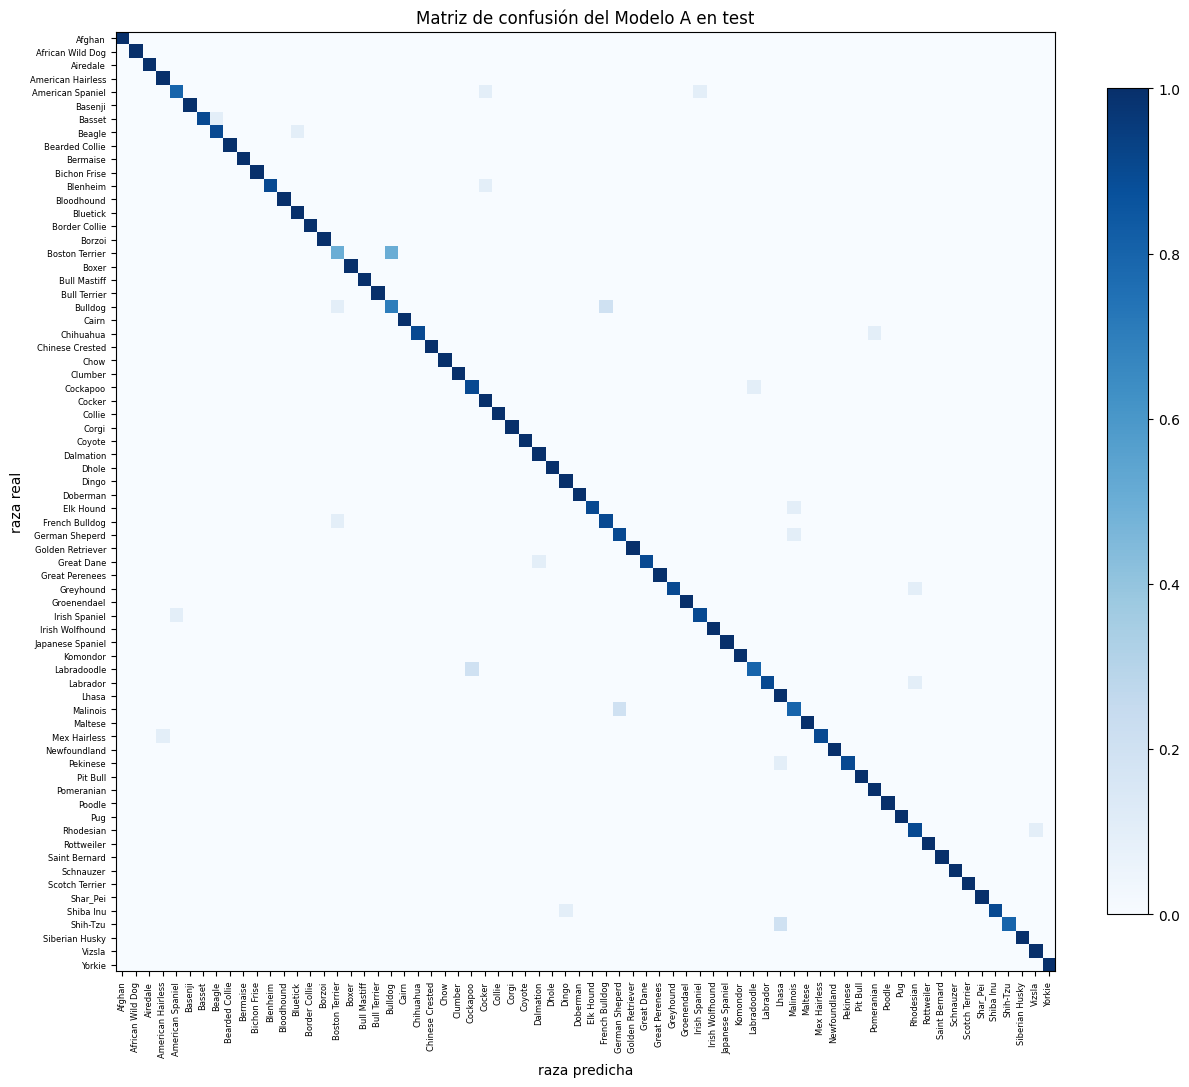

Errores en test: 32 de 700
     raza real         predicha  errores
Boston Terrier          Bulldog        5
      Shih-Tzu            Lhasa        2
   Labradoodle         Cockapoo        2
      Malinois   German Sheperd        2
       Bulldog   French Bulldog        2
     Rhodesian           Vizsla        1
      Pekinese            Lhasa        1
     Shiba Inu            Dingo        1
 Irish Spaniel American Spaniel        1
     Greyhound        Rhodesian        1


In [26]:
# Matriz de confusión normalizada por fila
cm_norm = cm_a / cm_a.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(12, 11))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)), classes, rotation=90, fontsize=6)
ax.set_yticks(range(len(classes)), classes, fontsize=6)
ax.set_xlabel("raza predicha")
ax.set_ylabel("raza real")
ax.set_title("Matriz de confusión del Modelo A en test")
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

# Pares de razas más confundidos (sin la diagonal)
errors_a = cm_a.copy()
np.fill_diagonal(errors_a, 0)
real, pred = np.unravel_index(np.argsort(-errors_a, axis=None)[:10], errors_a.shape)
pairs_a = pd.DataFrame({"raza real": np.array(classes)[real], "predicha": np.array(classes)[pred], "errores": errors_a[real, pred]})
print(f"Errores en test: {errors_a.sum()} de {cm_a.sum()}")
print(pairs_a[pairs_a["errores"] > 0].to_string(index=False))

La matriz es casi diagonal. Hay 32 errores en 700 imágenes y el par más confundido es Boston Terrier con Bulldog, con 5. El resto también son razas parecidas, como Shih-Tzu y Lhasa o Malinois y German Sheperd. Son los mismos grupos que fallaban en la búsqueda, pero con menos errores (32 contra 46 de la sección 3.7).

## 5. Modelo B (obligatorio): CNN propia

`train_classifier` con el modelo activo `cnn_custom` debe guardar el checkpoint en
`models/cnn_custom.pth` (o el nombre configurado en `CNN_CUSTOM_MODEL_NAME`).
Definí la arquitectura en un módulo importable (por ejemplo, `src/lib/models/cnn_custom.py`):
si la clase vive en la notebook, `torch.load` falla en la app.

### 5.1. Arquitectura

La red repite un mismo bloque varias veces. Cada bloque tiene convoluciones 3×3 sin bias, cada una seguida de BatchNorm y ReLU, y termina en un MaxPool que reduce la imagen a la mitad. Usamos 3×3 porque apilando varias se cubre una zona grande con menos parámetros que con un kernel grande. BatchNorm hace más estable el entrenamiento y permite un learning rate más alto, que importa al entrenar desde cero. Como ya agrega su propio desplazamiento, las convoluciones no necesitan bias.

Después del último bloque promediamos cada mapa con global average pooling en vez de aplanar. Si aplanáramos, los 256 mapas de 14×14 de E1 darían 50.176 valores y la capa siguiente tendría 25 millones de parámetros. Con el promedio tiene 131 mil. Sigue un embedding de 512 con ReLU, del mismo tamaño que el de la ResNet18 (`EMBEDDING_DIM`) para usarlo en la búsqueda por similitud, y un dropout de 0,3 antes del clasificador. La salida no lleva softmax porque `CrossEntropyLoss` ya lo aplica.

La clase está en `src/lib/models/cnn_custom.py` y no en la notebook, porque `torch.load` necesita importarla para cargar el checkpoint en la app.

Probamos dos tamaños, empezando por algo chico como sugiere el enunciado.
- E1, 4 bloques de una convolución, con 32, 64, 128 y 256 canales.
- E2, 5 bloques de dos convoluciones, con 32, 64, 128, 256 y 512 canales, para ver si con más capacidad aprende mejor las razas.

In [27]:
# Configuración de los experimentos y resumen de cada arquitectura
base_b = TRAIN_CONFIGS["cnn_custom"]
experiments = {
    "E1": replace(base_b, checkpoint=Path(settings.model_path) / "cnn_custom_e1.pth"),
    "E2": replace(base_b, channels=(32, 64, 128, 256, 512), convs_per_block=2, checkpoint=Path(settings.model_path) / "cnn_custom_e2.pth"),
}


def summarize(config: TrainConfig) -> pd.DataFrame:
    """Forma de la salida y parametros de cada parte de la red, para una imagen de IMAGE_SIZE."""
    model = CNNCustom(70, config.channels, config.convs_per_block, config.embedding_dim, config.dropout).eval()
    x = torch.zeros(1, 3, settings.image_size, settings.image_size)
    rows = []
    for i, block in enumerate(model.features, 1):
        x = block(x)
        rows.append((f"bloque {i}", tuple(x.shape[1:]), sum(p.numel() for p in block.parameters())))
    rows.append(("global average pooling", (x.shape[1],), 0))
    rows.append(("embedding", (config.embedding_dim,), sum(p.numel() for p in model.embedding.parameters())))
    rows.append(("clasificador", (70,), sum(p.numel() for p in model.fc.parameters())))
    return pd.DataFrame(rows, columns=["capa", "salida", "parámetros"])


for name, config in experiments.items():
    table = summarize(config)
    print(f"{name}: {table['parámetros'].sum():,} parámetros".replace(",", "."))
    print(table.to_string(index=False), end="\n\n")

E1: 556.390 parámetros
                  capa         salida  parámetros
              bloque 1 (32, 112, 112)         928
              bloque 2   (64, 56, 56)       18560
              bloque 3  (128, 28, 28)       73984
              bloque 4  (256, 14, 14)      295424
global average pooling         (256,)           0
             embedding         (512,)      131584
          clasificador          (70,)       35910

E2: 5.012.774 parámetros
                  capa         salida  parámetros
              bloque 1 (32, 112, 112)       10208
              bloque 2   (64, 56, 56)       55552
              bloque 3  (128, 28, 28)      221696
              bloque 4  (256, 14, 14)      885760
              bloque 5    (512, 7, 7)     3540992
global average pooling         (512,)           0
             embedding         (512,)      262656
          clasificador          (70,)       35910



E1 tiene 556 mil parámetros y E2 5 millones, la mayoría en el último bloque. Las dos son más chicas que la ResNet18 del Modelo A, que tiene 11,2 millones.

### 5.2. Experimentos

Usamos la misma receta que en el Modelo A, con algunos cambios porque la red arranca desde cero. El learning rate es 1e-3 en toda la red, porque no hay capas preentrenadas que cuidar. Damos hasta 50 épocas, ya que desde cero tarda mucho más en aprender, y más paciencia, 3 épocas para bajar el learning rate y 8 para cortar, porque las curvas son más ruidosas.

Cada experimento se guarda en su propio checkpoint y al final copiamos el mejor a `models/cnn_custom.pth`, que es el que usa la app.

In [28]:
# El modelo activo pasa a ser la CNN propia
classifier.set_active_model("cnn_custom")

# Hiperparámetros de cada experimento
print(pd.DataFrame({name: asdict(c) for name, c in experiments.items()}).drop("checkpoint").to_string())

                                 E1                       E2
strategy                    scratch                  scratch
augment                        True                     True
epochs                           50                       50
batch_size                       64                       64
lr_head                       0.001                    0.001
lr_backbone                   0.001                    0.001
weight_decay                 0.0001                   0.0001
label_smoothing                 0.1                      0.1
lr_patience                       3                        3
early_stopping                    8                        8
num_workers                       4                        4
seed                             42                       42
channels         (32, 64, 128, 256)  (32, 64, 128, 256, 512)
convs_per_block                   1                        2
embedding_dim                   512                      512
dropout                 

E1 y E2 solo cambian en la arquitectura, así la diferencia entre ellos se debe a la capacidad de la red.

#### E1, red chica

Entrenamos la red de 4 bloques.

In [29]:
# Entrenamiento de E1
TRAIN_CONFIGS["cnn_custom"] = experiments["E1"]
classifier.train_classifier()

Entrenando cnn_custom (scratch) en cuda, 556390 parametros entrenables


Epoca  1  train loss 4.090 acc 0.043  valid loss 4.108 acc 0.035  lr 1e-03  176 s  (mejor)


Epoca  2  train loss 3.925 acc 0.075  valid loss 3.760 acc 0.103  lr 1e-03  14 s  (mejor)


Epoca  3  train loss 3.790 acc 0.099  valid loss 3.617 acc 0.133  lr 1e-03  14 s  (mejor)


Epoca  4  train loss 3.684 acc 0.123  valid loss 3.593 acc 0.112  lr 1e-03  14 s  (mejor)


Epoca  5  train loss 3.604 acc 0.140  valid loss 3.448 acc 0.144  lr 1e-03  15 s  (mejor)


... (42 outputs left out)

Epoca 48  train loss 2.687 acc 0.377  valid loss 2.463 acc 0.437  lr 1e-04  15 s


Epoca 49  train loss 2.687 acc 0.378  valid loss 2.499 acc 0.398  lr 1e-04  15 s


Epoca 50  train loss 2.675 acc 0.386  valid loss 2.438 acc 0.436  lr 1e-04  14 s  (mejor)


Se guardaron cnn_custom_e1.pth y history_cnn_custom_e1.json


E1 aprende muy despacio. El learning rate bajó en la época 17, cuando todavía estaba mejorando, y llegó al tope de 50 épocas con 43,6 % en valid. Train queda por debajo de valid, así que no sobreajusta. Le falta capacidad para separar 70 razas.

#### E2, red más profunda y ancha

Entrenamos la red de 5 bloques de dos convoluciones.

In [30]:
# Entrenamiento de E2
TRAIN_CONFIGS["cnn_custom"] = experiments["E2"]
classifier.train_classifier()

Entrenando cnn_custom (scratch) en cuda, 5012774 parametros entrenables


Epoca  1  train loss 4.101 acc 0.039  valid loss 4.097 acc 0.032  lr 1e-03  198 s  (mejor)


Epoca  2  train loss 4.005 acc 0.054  valid loss 4.096 acc 0.032  lr 1e-03  137 s  (mejor)


Epoca  3  train loss 3.916 acc 0.068  valid loss 3.920 acc 0.063  lr 1e-03  67 s  (mejor)


Epoca  4  train loss 3.830 acc 0.086  valid loss 3.999 acc 0.067  lr 1e-03  56 s


Epoca  5  train loss 3.703 acc 0.112  valid loss 3.522 acc 0.131  lr 1e-03  55 s  (mejor)


... (42 outputs left out)

Epoca 48  train loss 1.662 acc 0.728  valid loss 1.652 acc 0.707  lr 1e-03  56 s


Epoca 49  train loss 1.624 acc 0.743  valid loss 1.485 acc 0.789  lr 1e-03  55 s  (mejor)


Epoca 50  train loss 1.601 acc 0.756  valid loss 1.522 acc 0.754  lr 1e-03  55 s


Se guardaron cnn_custom_e2.pth y history_cnn_custom_e2.json


Con más capas y canales la red aprende mucho mejor y llega a 78,9 % en valid, casi el doble que E1. Cada época tarda casi 4 veces más. Igual que E1, termina en el tope de 50 épocas todavía mejorando, y el learning rate nunca llegó a bajar.

#### E3, sin augmentation

Para ver cuánto aporta el augmentation, repetimos la mejor arquitectura de E1 y E2 (según la loss de valid) sin augmentation.

In [31]:
# La mejor arquitectura de E1 y E2 según la loss de valid, ahora sin augmentation
def load_history(checkpoint: Path) -> pd.DataFrame:
    path = Path(settings.output_path) / f"history_{checkpoint.stem}.json"
    return pd.DataFrame(json.loads(path.read_text(encoding="utf-8"))["history"])


best_arch = min(("E1", "E2"), key=lambda e: load_history(experiments[e].checkpoint)["valid_loss"].min())
experiments["E3"] = replace(experiments[best_arch], augment=False, checkpoint=Path(settings.model_path) / "cnn_custom_e3.pth")
print(f"E3 usa la arquitectura de {best_arch}")

E3 usa la arquitectura de E2


In [32]:
# Entrenamiento de E3
TRAIN_CONFIGS["cnn_custom"] = experiments["E3"]
classifier.train_classifier()

Entrenando cnn_custom (scratch) en cuda, 5012774 parametros entrenables


Epoca  1  train loss 4.065 acc 0.048  valid loss 3.947 acc 0.054  lr 1e-03  131 s  (mejor)


Epoca  2  train loss 3.863 acc 0.076  valid loss 3.914 acc 0.070  lr 1e-03  55 s  (mejor)


Epoca  3  train loss 3.705 acc 0.109  valid loss 3.550 acc 0.121  lr 1e-03  55 s  (mejor)


Epoca  4  train loss 3.536 acc 0.145  valid loss 3.532 acc 0.137  lr 1e-03  55 s  (mejor)


Epoca  5  train loss 3.392 acc 0.181  valid loss 3.517 acc 0.150  lr 1e-03  55 s  (mejor)


... (42 outputs left out)

Epoca 48  train loss 1.469 acc 0.824  valid loss 1.743 acc 0.692  lr 1e-05  53 s  (mejor)


Epoca 49  train loss 1.459 acc 0.829  valid loss 1.750 acc 0.690  lr 1e-05  53 s


Epoca 50  train loss 1.466 acc 0.827  valid loss 1.738 acc 0.692  lr 1e-05  55 s  (mejor)


Se guardaron cnn_custom_e3.pth y history_cnn_custom_e3.json


Sin augmentation, train sube más rápido y termina en 82,7 %, pero valid se queda en 69,2 %, contra 78,9 % de E2 con la misma red. La red memoriza las fotos de train en vez de aprender la raza. Con tan pocas fotos por raza, el augmentation es necesario para entrenar desde cero.

#### E4, más tiempo de entrenamiento

E1 y E2 llegaron al tope de 50 épocas con la mejor época al final, o sea que todavía estaban aprendiendo. Además, en E1 el learning rate bajó por un bache corto de valid cuando la red todavía mejoraba. Repetimos la mejor arquitectura con más margen.
- Hasta 100 épocas.
- Paciencia de 5 épocas para bajar el learning rate y de 10 para el early stopping, así un bache corto de valid no frena el entrenamiento.

In [33]:
# La mejor arquitectura de E1 y E2 con más épocas y más paciencia
experiments["E4"] = replace(experiments[best_arch], epochs=100, lr_patience=5, early_stopping=10,
                            checkpoint=Path(settings.model_path) / "cnn_custom_e4.pth")
print(pd.Series(asdict(experiments["E4"]))[["channels", "convs_per_block", "augment", "epochs", "lr_patience", "early_stopping"]].to_string())

channels           (32, 64, 128, 256, 512)
convs_per_block                          2
augment                               True
epochs                                 100
lr_patience                              5
early_stopping                          10


In [34]:
# Entrenamiento de E4
TRAIN_CONFIGS["cnn_custom"] = experiments["E4"]
classifier.train_classifier()

Entrenando cnn_custom (scratch) en cuda, 5012774 parametros entrenables


Epoca  1  train loss 4.102 acc 0.039  valid loss 4.020 acc 0.038  lr 1e-03  183 s  (mejor)


Epoca  2  train loss 4.003 acc 0.050  valid loss 3.973 acc 0.067  lr 1e-03  121 s  (mejor)


Epoca  3  train loss 3.914 acc 0.071  valid loss 3.833 acc 0.082  lr 1e-03  57 s  (mejor)


Epoca  4  train loss 3.819 acc 0.088  valid loss 4.009 acc 0.067  lr 1e-03  57 s


Epoca  5  train loss 3.697 acc 0.115  valid loss 3.582 acc 0.124  lr 1e-03  57 s  (mejor)


... (92 outputs left out)

Epoca 98  train loss 1.153 acc 0.930  valid loss 1.200 acc 0.875  lr 1e-05  62 s  (mejor)


Epoca 99  train loss 1.150 acc 0.930  valid loss 1.199 acc 0.876  lr 1e-05  62 s  (mejor)


Epoca 100  train loss 1.156 acc 0.929  valid loss 1.198 acc 0.882  lr 1e-05  62 s  (mejor)


Se guardaron cnn_custom_e4.pth y history_cnn_custom_e4.json


Con más tiempo, la misma red de E2 pasa de 78,9 % a 88,2 % en valid. Sigue mejorando hasta la época 64 con el learning rate en 1e-3, y cuando baja en la 65 da un salto. La mejor época es la 100, pero desde la 66 valid casi no cambia, así que esta vez sí llegó a su techo. A E2 le faltaba entrenamiento.

### 5.3. Curvas de entrenamiento

Graficamos la loss y la accuracy de train y valid de cada experimento, con la época elegida marcada.

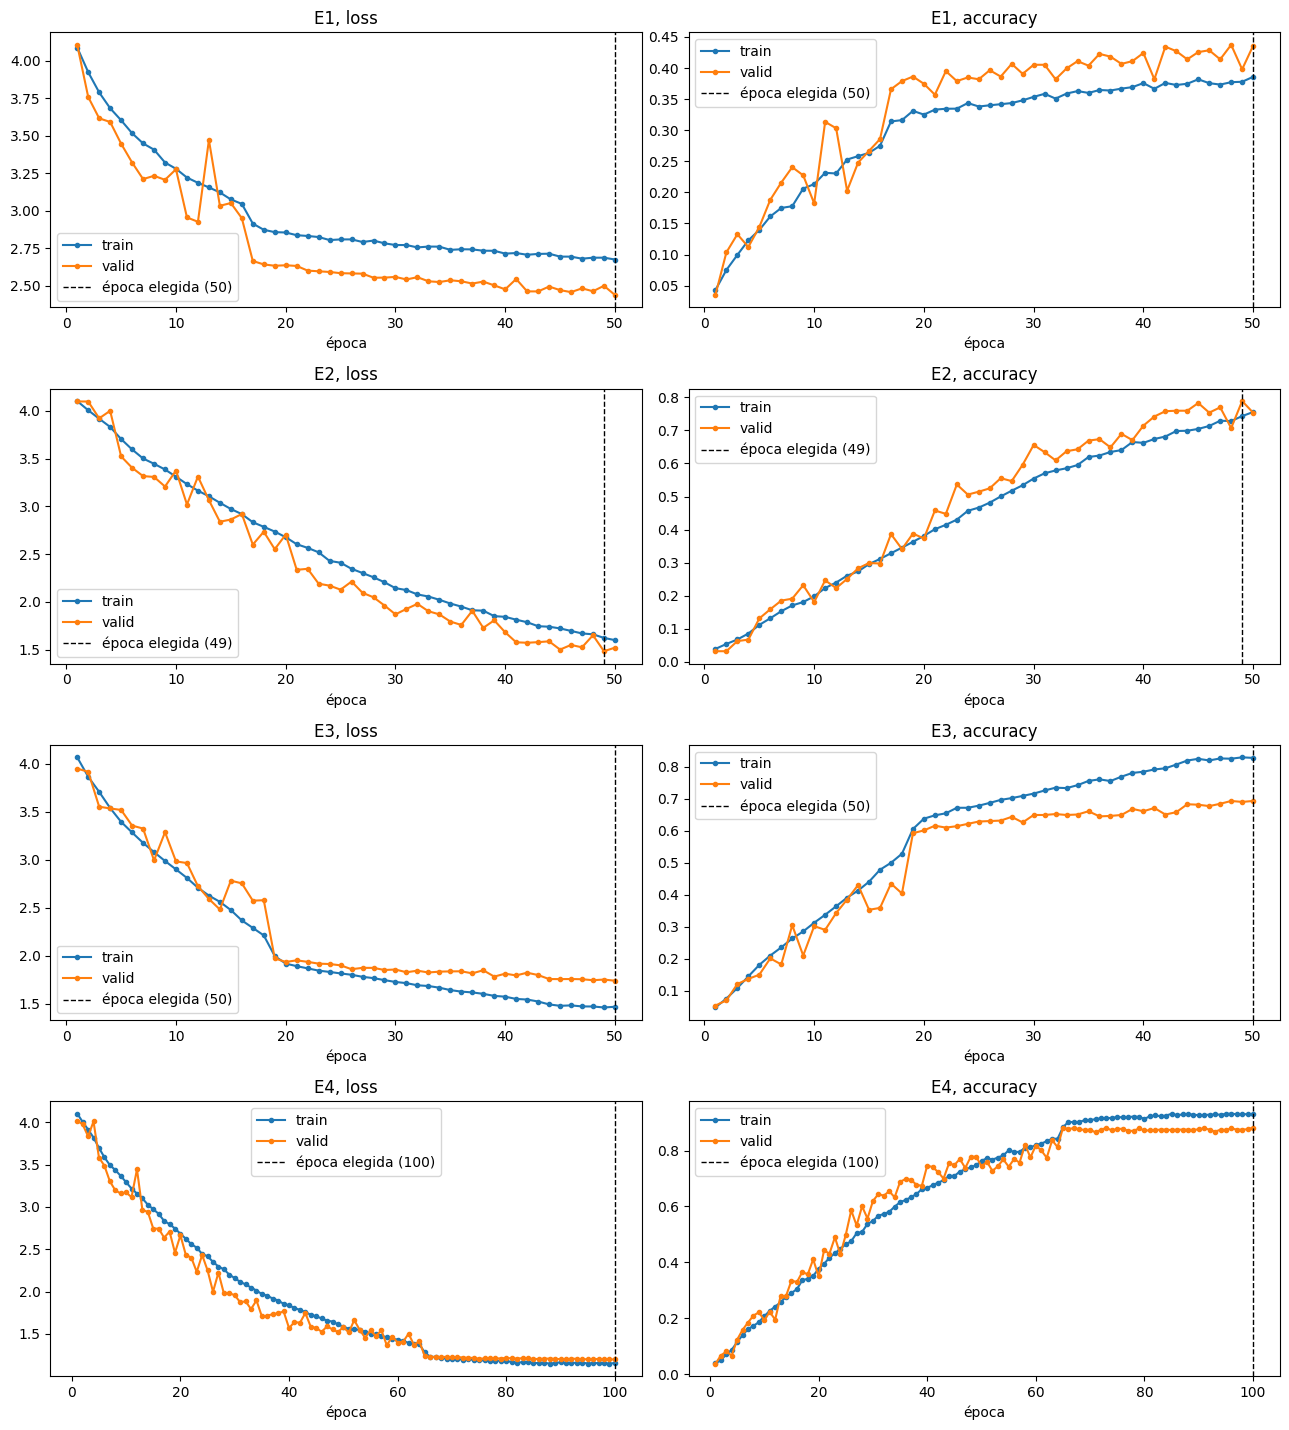

In [35]:
# Curvas de cada experimento
histories_b = {name: load_history(c.checkpoint) for name, c in experiments.items()}

fig, axes = plt.subplots(len(histories_b), 2, figsize=(13, 3.6 * len(histories_b)))
for row, (name, h) in enumerate(histories_b.items()):
    best = int(h.loc[h["valid_loss"].idxmin(), "epoch"])
    for col, metric in enumerate(("loss", "acc")):
        ax = axes[row, col]
        ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", ms=3, label="train")
        ax.plot(h["epoch"], h[f"valid_{metric}"], marker="o", ms=3, label="valid")
        ax.axvline(best, color="k", ls="--", lw=1, label=f"época elegida ({best})")
        ax.set_title(f"{name}, {'loss' if metric == 'loss' else 'accuracy'}")
        ax.set_xlabel("época")
        ax.legend()
plt.tight_layout()
plt.show()

En E1, E2 y E4 la accuracy de train queda por debajo o pegada a la de valid casi todo el entrenamiento, porque train se mide con augmentation y dropout. Recién al final de E4 train pasa a valid (92,9 % contra 88,2 %), un overfitting chico. E3 es el único con overfitting claro, desde la época 20 train y valid se separan cada vez más. La primera vez que baja el learning rate, valid deja de saltar y mejora de golpe.

### 5.4. Tabla de experimentos

Comparamos los experimentos en su mejor época. La diferencia entre la accuracy de train y la de valid muestra cuánto sobreajusta cada uno. El de menor loss de valid pasa a ser el Modelo B.

In [36]:
# Resumen de cada experimento en su mejor época según la loss de valid
changes = {"E1": "4 bloques x1 conv", "E2": "5 bloques x2 conv", "E3": f"{best_arch} sin augmentation",
           "E4": f"{best_arch} con 100 épocas y más paciencia"}
rows = {}
for name, h in histories_b.items():
    best = h.loc[h["valid_loss"].idxmin()]
    c = experiments[name]
    rows[name] = {
        "cambio": changes[name],
        "parámetros": sum(p.numel() for p in CNNCustom(70, c.channels, c.convs_per_block, c.embedding_dim, c.dropout).parameters()),
        "mejor época": int(best["epoch"]),
        "épocas": len(h),
        "train acc": round(best["train_acc"], 3),
        "valid acc": round(best["valid_acc"], 3),
        "valid loss": round(best["valid_loss"], 3),
        "minutos": round(h["seconds"].sum() / 60, 1),
    }
table_b = pd.DataFrame(rows).T
print(table_b.to_string())

# El mejor experimento pasa a ser el checkpoint que usa la app
best_b = table_b["valid loss"].astype(float).idxmin()
shutil.copy(experiments[best_b].checkpoint, classifier.checkpoints["cnn_custom"])
print(f"\nModelo B elegido: {best_b}, copiado a {classifier.checkpoints['cnn_custom'].name}")

                               cambio parámetros mejor época épocas train acc valid acc valid loss minutos
E1                  4 bloques x1 conv     556390          50     50     0.386     0.436      2.438    14.8
E2                  5 bloques x2 conv    5012774          49     50     0.743     0.789      1.485    50.9
E3                E2 sin augmentation    5012774          50     50     0.827     0.692      1.738    47.2
E4  E2 con 100 épocas y más paciencia    5012774         100    100     0.929     0.882      1.198    99.7



Modelo B elegido: E4, copiado a cnn_custom.pth


El Modelo B es E4, con la menor loss de valid (1,198) y 88,2 % de accuracy. Lo que más sumó fue la capacidad, de E1 a E2 valid pasa de 43,6 % a 78,9 %. Después, entrenar más tiempo, que es lo que separa a E2 de E4. Sin augmentation (E3) valid cae a 69,2 % y aparece overfitting. E4 tardó 100 minutos en entrenar, contra 10 del Modelo A.

### 5.5. Métricas en `test`

Evaluamos el experimento elegido con `evaluate_classifier`, igual que el Modelo A.

In [37]:
# Métricas del Modelo B en test, al lado de las del Modelo A
metrics_b = classifier.evaluate_classifier()
print(pd.DataFrame({"Modelo A": metrics_a, "Modelo B": metrics_b}).round(4).to_string())

Test de cnn_custom: {'accuracy': 0.88, 'precision': 0.8908, 'recall': 0.88, 'specificity': 0.9983, 'f1': 0.8789}


             Modelo A  Modelo B
accuracy       0.9543    0.8800
precision      0.9572    0.8908
recall         0.9543    0.8800
specificity    0.9993    0.9983
f1             0.9542    0.8789


En `test` el Modelo B acierta el 88,0 %, con F1 macro de 0,879, parecido a valid (88,2 %). El Modelo A, con el doble de parámetros, acierta el 95,4 % y entrena en la décima parte del tiempo. Los experimentos explican la diferencia. La ResNet ya sabe reconocer bordes, texturas y partes de animales por ImageNet, que además tiene muchas razas de perros, y la CNN propia tiene que aprender todo eso con 7.539 fotos. Con unas 108 fotos por raza, sin augmentation la red sobreajusta (E3), y la red chica (E1) no alcanzó ni para aprender train.

#### Razas con peor desempeño

Las 10 razas con peor F1 del Modelo B.

In [38]:
# Predicciones de test y métricas por raza del Modelo B
pred_b = predict(classifier.load_model(), DATASET, test_a, settings.image_size).argmax(1)
cm_b = confusion(test_a["label"].to_numpy(), pred_b, len(classes))

per_breed_b = per_class_metrics(cm_b).set_index(pd.Index(classes, name="raza"))
print(per_breed_b.sort_values("f1").head(10).round(3).to_string())

                precision  recall  specificity     f1  support
raza                                                          
Cockapoo            0.625     0.5        0.996  0.556       10
Lhasa               0.750     0.6        0.997  0.667       10
Malinois            0.636     0.7        0.994  0.667       10
Labradoodle         0.615     0.8        0.993  0.696       10
Cocker              0.778     0.7        0.997  0.737       10
Saint Bernard       1.000     0.6        1.000  0.750       10
German Sheperd      0.727     0.8        0.996  0.762       10
Shih-Tzu            0.727     0.8        0.996  0.762       10
Bull Terrier        0.875     0.7        0.999  0.778       10
Chihuahua           0.875     0.7        0.999  0.778       10


Las peores vuelven a ser grupos de razas parecidas, como Cockapoo y Labradoodle, Malinois y German Sheperd o Lhasa y Shih-Tzu. También aparecen razas que el Modelo A no confundía, como Saint Bernard, con recall de 0,6.

#### Matriz de confusión

La misma matriz normalizada por fila que en el Modelo A, y los pares más confundidos.

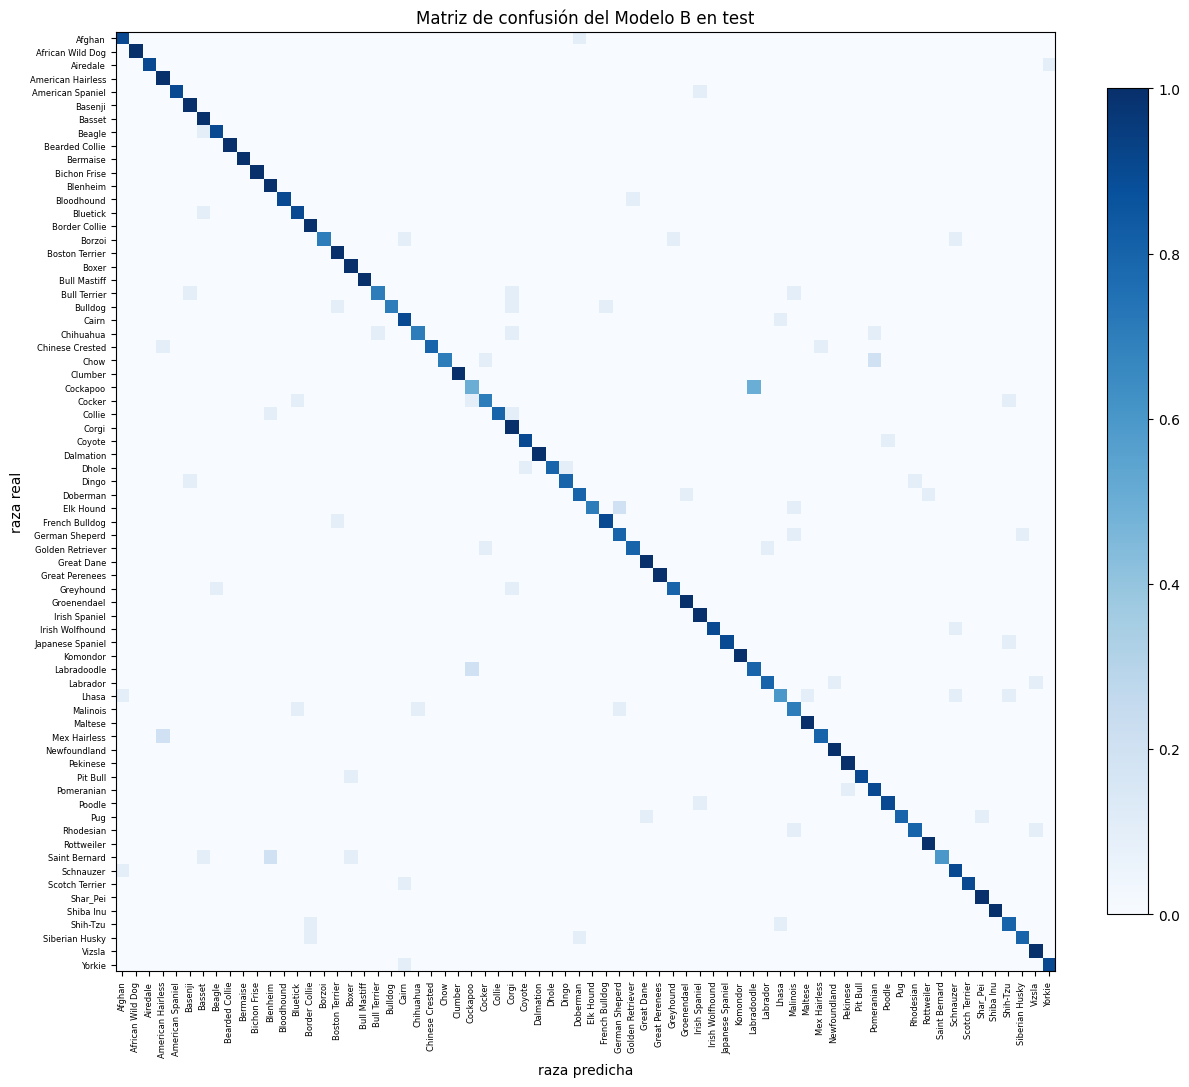

Errores en test: 84 de 700
    raza real          predicha  errores
     Cockapoo       Labradoodle        5
Saint Bernard          Blenheim        2
  Labradoodle          Cockapoo        2
 Mex Hairless American Hairless        2
    Elk Hound    German Sheperd        2
         Chow        Pomeranian        2
     Shih-Tzu     Border Collie        1
       Yorkie             Cairn        1
Saint Bernard            Basset        1
Saint Bernard             Boxer        1


In [39]:
# Matriz de confusión normalizada por fila del Modelo B
cm_norm_b = cm_b / cm_b.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(12, 11))
im = ax.imshow(cm_norm_b, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)), classes, rotation=90, fontsize=6)
ax.set_yticks(range(len(classes)), classes, fontsize=6)
ax.set_xlabel("raza predicha")
ax.set_ylabel("raza real")
ax.set_title("Matriz de confusión del Modelo B en test")
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

# Pares de razas más confundidos (sin la diagonal)
errors_b = cm_b.copy()
np.fill_diagonal(errors_b, 0)
real, pred = np.unravel_index(np.argsort(-errors_b, axis=None)[:10], errors_b.shape)
pairs_b = pd.DataFrame({"raza real": np.array(classes)[real], "predicha": np.array(classes)[pred], "errores": errors_b[real, pred]})
print(f"Errores en test: {errors_b.sum()} de {cm_b.sum()}")
print(pairs_b[pairs_b["errores"] > 0].to_string(index=False))

Hay 84 errores en 700 imágenes, contra 32 del Modelo A, y el par más confundido es Cockapoo con Labradoodle, con 5. A diferencia del Modelo A, aparecen errores entre razas que no se parecen tanto, como Saint Bernard con Blenheim, Basset o Boxer. Nuestra hipótesis es que, sin preentrenamiento, la red se apoya más en el color del pelaje que en la forma.

## 6. Evaluación sobre el conjunto independiente

Medimos los dos modelos con las 124 fotos de un perro del conjunto independiente, con las mismas métricas que en `test`. Como solo aparecen 20 de las 70 razas, precision, recall, specificity y F1 se promedian sobre esas 20.

In [40]:
# Métricas de cada modelo en test y en el conjunto independiente
def present_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    """Accuracy y métricas macro sobre las razas que tienen imágenes."""
    per_class = per_class_metrics(confusion(y_true, y_pred, len(classes)))
    per_class = per_class[per_class["support"] > 0]
    return {"accuracy": float((y_true == y_pred).mean()), **per_class[["precision", "recall", "specificity", "f1"]].mean().to_dict()}


ind_eval = ind_dogs.assign(label=ind_dogs["breed"].map({breed: i for i, breed in enumerate(classes)}))
models_ab = {"Modelo A": "resnet18_finetuned", "Modelo B": "cnn_custom"}

preds_ab = {}
for label, name in models_ab.items():
    classifier.set_active_model(name)
    model = classifier.load_model()
    for split, df in (("test", test_a), ("independiente", ind_eval)):
        preds_ab[label, split] = predict(model, DATASET, df, settings.image_size).argmax(1)

table_ind = pd.DataFrame({
    f"{label} {split}": present_metrics(df["label"].to_numpy(), preds_ab[label, split])
    for label in models_ab for split, df in (("test", test_a), ("independiente", ind_eval))
})
print(table_ind.round(3).to_string())
print(f"\nBúsqueda del baseline, accuracy en test {results['test']['correct'].mean():.3f} y en el independiente {results['independent']['correct'].mean():.3f}")

             Modelo A test  Modelo A independiente  Modelo B test  Modelo B independiente
accuracy             0.954                   0.444          0.880                   0.250
precision            0.957                   0.740          0.891                   0.465
recall               0.954                   0.444          0.880                   0.268
specificity          0.999                   0.997          0.998                   0.994
f1                   0.954                   0.523          0.879                   0.325

Búsqueda del baseline, accuracy en test 0.934 y en el independiente 0.621


En el conjunto independiente los dos modelos caen mucho. El Modelo A pasa de 95,4 % en `test` a 44,4 % y el B de 88,0 % a 25,0 %, y los dos quedan por debajo de la búsqueda del baseline, que en las mismas fotos acierta el 62,1 %.

Creemos que la caída viene del cambio de dominio. Las fotos del dataset son recortes donde el perro ocupa casi toda la imagen, y las del conjunto independiente son fotos de internet con el perro en su ambiente, con fondo, gente u objetos. Los modelos se entrenaron solo con recortes y no aprendieron a ignorar el fondo, algo que ya pasaba con la búsqueda. Igual son solo 124 fotos, así que estos valores tienen bastante ruido.

### 6.1. Prueba sin fondo

Si el problema es el fondo, recortar el perro antes de clasificar debería recuperar parte de la accuracy. Clasificamos el recorte de la caja más confiable de YOLO en cada foto, y si no encuentra perro, la foto entera. A la búsqueda del baseline le damos el mismo recorte.

In [41]:
# Accuracy con la foto entera y con el recorte del perro
detection = build_detection(settings, classifier)


def dog_crop(path: str) -> tuple[np.ndarray, bool]:
    """Recorte del perro más confiable según YOLO y si lo encontró. Sin perro devuelve la foto entera."""
    image = load_bgr(DATASET / path)
    detections = detection.detect_dogs(image)
    if not detections:
        return image, False
    x1, y1, x2, y2 = detections[0][0]
    return image[y1:y2, x1:x2], True


crops, found = zip(*(dog_crop(path) for path in ind_eval["path"]))
print(f"YOLO encontró perro en {sum(found)} de {len(found)} fotos\n")

breeds = ind_eval["breed"].to_numpy()
Q_crops = np.array([similarity.extract_embedding(c) for c in crops], dtype=np.float32)
crop_rows = {"Búsqueda baseline": (results["independent"]["correct"].mean(),
                                   evaluate(ind_eval, Q_crops, "cosine", top_k=settings.top_k)["correct"].mean())}
for label, name in models_ab.items():
    classifier.set_active_model(name)
    preds = np.array([detection.classify_detected_dog(c)[0] for c in crops])
    full = preds_ab[label, "independiente"] == ind_eval["label"].to_numpy()
    crop_rows[label] = (full.mean(), (preds == breeds).mean())

print(pd.DataFrame(crop_rows, index=["foto entera", "recorte"]).T.round(3).to_string())

Detector YOLO cargado: models/yolo11n.pt


YOLO encontró perro en 119 de 124 fotos



Baseline ResNet18 (ImageNet) cargado en cuda


                   foto entera  recorte
Búsqueda baseline        0.621    0.742
Modelo A                 0.444    0.669
Modelo B                 0.250    0.452


Con el recorte las tres mejoran mucho. El Modelo A pasa de 44,4 % a 66,9 %, el B de 25,0 % a 45,2 % y la búsqueda del baseline de 62,1 % a 74,2 %. Buena parte de la caída viene del fondo. Igual siguen lejos de `test`, porque quedan otras diferencias con el dataset, como la pose, la luz o la calidad de la foto.

## 7. Embeddings de los modelos entrenados

Repetimos la búsqueda de la Etapa 1 cambiando los embeddings del baseline por los de los modelos A y B, que son la salida de la capa anterior al clasificador. La galería, las consultas y el voto son los mismos de la sección 3, así la diferencia se debe solo a la red que genera los vectores.

### 7.1. Embeddings de los modelos A y B

Calculamos los embeddings de train, `test` y el conjunto independiente con `extract_custom_embedding`, la misma función que usa la app cuando `EMBEDDING_MODEL` no es el baseline. Los guardamos en disco para no recalcularlos en cada corrida.

In [42]:
# Embeddings de cada modelo, guardados de una corrida anterior
emb_models = {"Baseline": emb}
for label, name in models_ab.items():
    cache_path = PROCESSED / f"embeddings_{name}.npz"
    cached = dict(np.load(cache_path, allow_pickle=True)) if cache_path.exists() else {}
    classifier.set_active_model(name)
    emb_models[label] = {}
    for split in ("train", "test", "independent"):
        paths = subsets[split]["path"].to_numpy()
        if split in cached and np.array_equal(cached[f"{split}_paths"], paths):
            emb_models[label][split] = cached[split]
        else:
            emb_models[label][split] = np.array([classifier.extract_custom_embedding(load_bgr(DATASET / p)) for p in paths], dtype=np.float32)
    np.savez(cache_path, **emb_models[label], **{f"{s}_paths": subsets[s]["path"].to_numpy() for s in emb_models[label]})

for label, e in emb_models.items():
    for split in ("train", "test", "independent"):
        print(f"{label:9s} {split:12s} {e[split].shape}  norma media {np.linalg.norm(e[split], axis=1).mean():.3f}")

Baseline  train        (7539, 512)  norma media 1.000
Baseline  test         (700, 512)  norma media 1.000
Baseline  independent  (124, 512)  norma media 1.000
Modelo A  train        (7539, 512)  norma media 1.000
Modelo A  test         (700, 512)  norma media 1.000
Modelo A  independent  (124, 512)  norma media 1.000
Modelo B  train        (7539, 512)  norma media 1.000
Modelo B  test         (700, 512)  norma media 1.000
Modelo B  independent  (124, 512)  norma media 1.000


Los embeddings de los modelos A y B tienen 512 valores y norma 1, igual que los del baseline, así que entran en la misma búsqueda y en la misma base vectorial sin cambiar `EMBEDDING_DIM`.

### 7.2. NDCG@10 con cada embedding

Buscamos los 10 vecinos de cada consulta de `test` y del conjunto independiente en la galería de train, con similitud coseno, y calculamos las mismas métricas de la sección 3.3.

In [43]:
# NDCG@10, precision@10 y accuracy de la búsqueda con cada embedding
results_emb = {}
for label, e in emb_models.items():
    for split, name in (("test", "test"), ("independiente", "independent")):
        results_emb[label, split] = evaluate(subsets[name], e[name], "cosine", top_k=settings.top_k, gallery_emb=e["train"])

table_emb = pd.DataFrame({key: summary(res) for key, res in results_emb.items()}).T.drop(columns="unknown")
table_emb.index.names = ["embedding", "consultas"]
print(table_emb.round(3).to_string())

                         NDCG@10  precision@10  accuracy
embedding consultas                                     
Baseline  test             0.873         0.860     0.934
          independiente    0.572         0.568     0.621
Modelo A  test             0.953         0.952     0.966
          independiente    0.476         0.479     0.516
Modelo B  test             0.836         0.829     0.861
          independiente    0.222         0.223     0.234


En `test` los embeddings del Modelo A son los mejores, con NDCG@10 de 0,953 contra 0,873 del baseline, y la búsqueda acierta el 96,6 %, un poco más que el propio clasificador del Modelo A (95,4 %). El entrenamiento acercó entre sí las imágenes de la misma raza, y eso mejora los vecinos aunque la red se haya entrenado para clasificar y no para buscar. Los del Modelo B quedan por debajo del baseline, con 0,836.

En el conjunto independiente el orden se invierte y el baseline vuelve a ganar, con 0,572 contra 0,476 del A y 0,222 del B. Es lo mismo que pasó con los clasificadores en el conjunto independiente. Los embeddings ajustados a los recortes del dataset andan muy bien con imágenes parecidas y peor con fotos reales.

### 7.3. Visualización con t-SNE

Proyectamos a 2 dimensiones los embeddings de `test` de 10 razas. Elegimos grupos que se confunden entre sí (Boston Terrier, Bulldog y French Bulldog, Malinois y German Sheperd, Cockapoo y Labradoodle, Lhasa y Shih-Tzu) y una raza fácil, Dalmation. Usamos t-SNE porque PCA es una proyección lineal y con tantas razas los grupos quedan encimados.

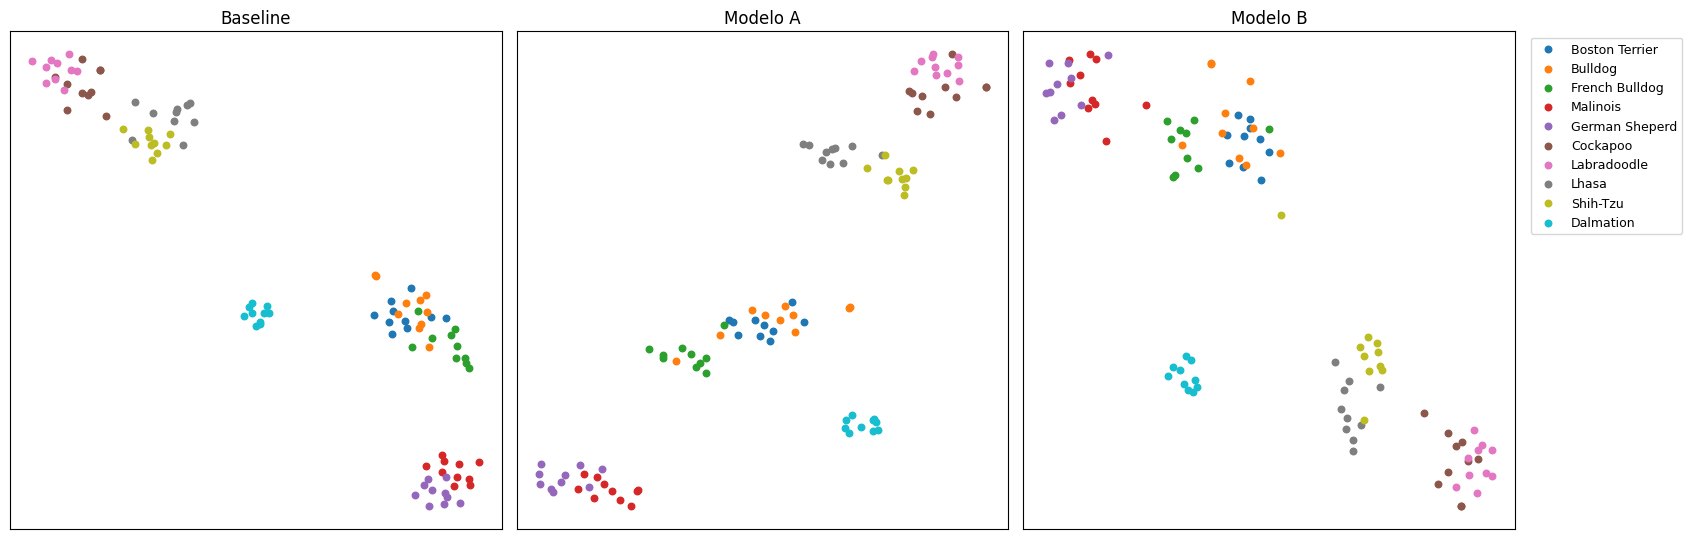

In [44]:
# t-SNE de los embeddings de test de 10 razas, las mismas en los tres gráficos
TSNE_BREEDS = ["Boston Terrier", "Bulldog", "French Bulldog", "Malinois", "German Sheperd",
               "Cockapoo", "Labradoodle", "Lhasa", "Shih-Tzu", "Dalmation"]
test_breeds = subsets["test"]["breed"].to_numpy()
mask = np.isin(test_breeds, TSNE_BREEDS)
colors = dict(zip(TSNE_BREEDS, plt.cm.tab10.colors))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (label, e) in zip(axes, emb_models.items()):
    points = TSNE(n_components=2, perplexity=20, init="pca", random_state=SEED).fit_transform(e["test"][mask])
    for breed in TSNE_BREEDS:
        sel = test_breeds[mask] == breed
        ax.scatter(points[sel, 0], points[sel, 1], s=22, color=colors[breed], label=breed)
    ax.set_title(label)
    ax.set_xticks([])
    ax.set_yticks([])
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

Dalmation queda separada en los tres, porque no se parece a ninguna otra raza del grupo. Con el baseline las razas parecidas quedan pegadas o mezcladas, como Boston Terrier, Bulldog y French Bulldog o Cockapoo y Labradoodle. Con el Modelo A los grupos son más compactos y se separan mejor, French Bulldog queda aparte y Cockapoo y Labradoodle forman dos grupos. Boston Terrier y Bulldog siguen mezclados, que es justo el par que más confunde el Modelo A. Con el Modelo B se separan algunas razas, pero Malinois y German Sheperd quedan mezclados, igual que Cockapoo y Labradoodle.

## 8. Análisis de errores

TO-DO: ejemplos de falsos positivos y falsos negativos con la imagen y su score, razas con peor
desempeño e hipótesis sobre las causas.

In [ ]:
## TO-DO: análisis de errores con ejemplos visuales.

## 9. Costo computacional

TO-DO: cantidad de parámetros, tamaño en MB, tiempo de inferencia por imagen en CPU y dimensión
del embedding de cada modelo.

In [ ]:
## TO-DO: costo computacional de cada modelo.

## 10. Comparación y elección final

TO-DO:
- Tabla comparativa de todas las métricas (Modelo A, Modelo B y baseline en la Etapa 1).
- Qué modelo usa la app para clasificar (Etapas 2 y 3) y qué embeddings para la búsqueda
  (`EMBEDDING_MODEL`), con su justificación.
- Búsqueda por similitud vs. clasificación supervisada: ventajas, limitaciones y cuándo conviene cada una.
- Trade-offs entre precisión, velocidad de inferencia, memoria y complejidad.

In [ ]:
## TO-DO: tabla comparativa final.

## 11. Descargar los checkpoints

Descargalos y colocalos en `models/` de tu entorno local para que la aplicación los use.
Recordá publicarlos en un link público de solo lectura y ponerlo en el README y en el PR.

In [ ]:
!ls -lh models/

try:
    from google.colab import files

    files.download(str(settings.model_path / settings.resnet18_model_name))
    files.download(str(settings.model_path / settings.cnn_custom_model_name))
except ImportError:
    print("Fuera de Colab: los checkpoints quedan en models/")